> Versión de portafolio. Se conservan las salidas históricas del trabajo académico. Las rutas absolutas de datos, cuando existían, se sustituyeron por nombres locales. Esta versión no se ha ejecutado de nuevo; consulte README y DATOS.md antes de reproducir.


# Proyecto empresa aliada · Entrega final
**Javier Bueno Sánchez | Ciencia de Datos | 18 de octubre de 2026**

## 1. Contexto y decisión
Analizar ventas de productos de consumo para priorizar surtido y áreas comerciales y estimar ventas futuras de **VANISH** y **LYSOL**. Se integran Python/Pandas, visualizaciones Matplotlib/Seaborn, K-Means, consultas SQL Server y el informe Power BI del entregable 5.

**Alcance:** datos históricos, no ventas actuales de 2026. Los pronósticos se originan en julio de 2023. Se conserva la unidad original de TOTAL_VALUE_SALES: la fuente no acredita moneda ni escala. Las marcas se filtran por igualdad exacta; no se suman automáticamente otras etiquetas que contengan VANISH.

**Reproducibilidad:** extraer el ZIP completo y ejecutar desde esta carpeta. Dependencias en requirements.txt. Los gráficos y resultados también se guardan como archivos. Las capturas SQL provienen del entregable 4; las de Power BI son evidencias reales del trabajo anterior, no simulaciones.

In [1]:
from pathlib import Path
import json, warnings, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

ROOT=Path('.'); DATA=ROOT/'data'; OUT=ROOT/'resultados'; FIG=ROOT/'graficos'
OUT.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', palette=['#3A7BD5','#6E7A89','#E19739','#2F876D'])
plt.rcParams.update({'figure.figsize':(11,4.5),'axes.spines.top':False,'axes.spines.right':False})
def finish(name):
    plt.tight_layout(); plt.savefig(FIG/f'{name}.png',dpi=180,bbox_inches='tight'); plt.close(); display(Image(filename=str(FIG/f'{name}.png'),width=1050))
f=pd.read_csv(DATA/'FACT_SALES(1).csv',dtype={'WEEK':str,'ITEM_CODE':str})
p=pd.read_excel(DATA/'DIM_PRODUCT(1).xlsx',dtype={'ITEM':str})
t=pd.read_excel(DATA/'DIM_CALENDAR (4)(1).xlsx',dtype={'WEEK':str})
g=pd.read_csv(DATA/'DIM_CATEGORY(1).csv')
s=pd.read_excel(DATA/'DIM_SEGMENT(1).xlsx')
tables={'FACT_SALES':f,'DIM_PRODUCT':p,'DIM_CALENDAR':t,'DIM_CATEGORY':g,'DIM_SEGMENT':s}
print('Python',platform.python_version())
display(pd.DataFrame([{'Tabla':k,'Filas':len(v),'Columnas':len(v.columns),
                       'Nulos':int(v.isna().sum().sum()),'Duplicados exactos':int(v.duplicated().sum())} for k,v in tables.items()]))

Python 3.12.14


          Tabla   Filas  Columnas  Nulos  Duplicados exactos
0    FACT_SALES  122002         6      0                   0
1   DIM_PRODUCT     505         9     14                   0
2  DIM_CALENDAR     156         5      0                   0
3  DIM_CATEGORY       5         2      0                   0
4   DIM_SEGMENT      53         6      1                   0

## 2. Limpieza, transformación e integridad
Los identificadores son texto para conservar ceros iniciales y sufijos. Se inspeccionan nulos y duplicados antes de intervenir. Las filas de catálogo sin ITEM se separan; no se inventan claves. Se estandarizan espacios, mayúsculas y saltos de línea literales. Las medidas numéricas se validan sin imputar ceros ni eliminar extremos comerciales.

DIM_SEGMENT se une por la clave compuesta CATEGORY, ATTR1, ATTR2, ATTR3, FORMAT. Cada unión se valida como muchos-a-uno para impedir que multiplique las ventas.

In [2]:
keys=['CATEGORY','ATTR1','ATTR2','ATTR3','FORMAT']
missing_item=p[p.ITEM.isna()].copy(); missing_item.to_csv(OUT/'productos_sin_clave.csv',index=False)
for df in (f,p,t,g,s):
    for col in df.select_dtypes(include=['object','string']):
        df[col]=df[col].astype('string').str.replace(r'\r\n|\n|\r',' ',regex=True).str.replace(r'\s+',' ',regex=True).str.strip().str.upper()
p=p.dropna(subset=['ITEM']).copy()
assert p.ITEM.is_unique and t.WEEK.is_unique and g.ID_CATEGORY.is_unique
assert not f.duplicated(['WEEK','ITEM_CODE','REGION']).any()
assert not s.duplicated(keys).any()
assert f[['WEEK','ITEM_CODE','REGION']].notna().all().all()
for col in ['TOTAL_UNIT_SALES','TOTAL_VALUE_SALES','TOTAL_UNIT_AVG_WEEKLY_SALES']:
    f[col]=pd.to_numeric(f[col],errors='raise')
assert f.notna().all().all()
assert (f[['TOTAL_UNIT_SALES','TOTAL_VALUE_SALES']]>=0).all().all()
t['DATE']=pd.to_datetime(t.DATE,errors='raise')
g=g.rename(columns={'CATEGORY':'CATEGORY_NAME'})
for col in keys[1:]:
    p[col]=p[col].fillna('NO DOCUMENTADO'); s[col]=s[col].fillna('NO DOCUMENTADO')
assert f.ITEM_CODE.isin(p.ITEM).all() and f.WEEK.isin(t.WEEK).all()
d=f.merge(p,left_on='ITEM_CODE',right_on='ITEM',validate='many_to_one')
d=d.merge(t[['WEEK','DATE','YEAR','MONTH','WEEK_NUMBER']],on='WEEK',validate='many_to_one')
d=d.merge(g,left_on='CATEGORY',right_on='ID_CATEGORY',validate='many_to_one')
d=d.merge(s[keys+['SEGMENT']],on=keys,how='left',validate='many_to_one')
print('Productos sin clave separados:',len(missing_item))
print('Segmentos no vinculados en hechos:',d.SEGMENT.isna().sum())
assert len(d)==len(f) and d.SEGMENT.notna().all()
mx=d[d.REGION.eq('TOTAL AUTOS SCANNING MEXICO')].copy()
a=d[~d.REGION.eq('TOTAL AUTOS SCANNING MEXICO')].copy()
recon=(mx.groupby(['WEEK','ITEM_CODE'])[['TOTAL_VALUE_SALES','TOTAL_UNIT_SALES']].sum()
       -a.groupby(['WEEK','ITEM_CODE'])[['TOTAL_VALUE_SALES','TOTAL_UNIT_SALES']].sum()).abs()
assert recon.notna().all().all() and recon.max().max()<0.003
weekly=mx.groupby(['DATE','BRAND']).TOTAL_VALUE_SALES.sum().unstack(fill_value=0).sort_index()
assert len(weekly)==80
display(recon.max().to_frame('Máxima diferencia nacional vs áreas'))
print('Fechas:',mx.DATE.min().date(),mx.DATE.max().date(),'| Categorías observadas:',mx.CATEGORY_NAME.nunique())
display(pd.DataFrame({'universo':['Todas las filas (no sumar para KPI)','Nacional','Seis áreas'],
                      'filas':[len(d),len(mx),len(a)],
                      'valor':[d.TOTAL_VALUE_SALES.sum(),mx.TOTAL_VALUE_SALES.sum(),a.TOTAL_VALUE_SALES.sum()]}))
d.to_csv(OUT/'ventas_consolidadas.csv',index=False)
for name,df in [('DIM_PRODUCT',p),('DIM_CATEGORY',g),('DIM_CALENDAR',t),('DIM_SEGMENT',s),('FACT_SALES',f)]:
    df.to_csv(OUT/f'{name}_limpio.csv',index=False)

Productos sin clave separados: 2
Segmentos no vinculados en hechos: 0
Fechas: 2022-01-09 2023-07-17 | Categorías observadas: 1


                   Máxima diferencia nacional vs áreas
TOTAL_VALUE_SALES                                0.002
TOTAL_UNIT_SALES                                 0.002

                              universo   filas         valor
0  Todas las filas (no sumar para KPI)  122002  1.104286e+07
1                             Nacional   20990  5.521429e+06
2                           Seis áreas  101012  5.521431e+06

## 3. Exploración: mercado, áreas, distribución y atípicos
El KPI nacional utiliza únicamente TOTAL AUTOS SCANNING MEXICO; las comparaciones regionales utilizan solo las seis áreas. Existe una categoría con ventas: no se construye una comparación artificial entre las cinco categorías del catálogo. Los boxplots e histogramas por categoría se muestran para evidenciar esta limitación.

Los valores elevados se marcan mediante IQR, sin asumir errores. Se utiliza log1p para visualizar la asimetría; no cambia los totales de negocio.

Umbral IQR nacional: 608.866 | Registros marcados: 2031
Advertencia: julio de 2023 contiene solo 3.0 semanas observadas.


             Participación nacional %
BRAND                                
CLORALEX                        48.84
VANISH                          19.64
CLOROX                          12.42
BLANCATEL                        5.91
OXI CLEAN                        3.96
DR.BECKMANN                      2.53
BANDERA                          2.44
LOS PATITOS                      1.29
CLARASOL                         1.28
LYSOL                            0.64

                    Participación áreas %
REGION                                   
TOTAL AUTOS AREA 2                  21.53
TOTAL AUTOS AREA 5                  20.89
TOTAL AUTOS AREA 6                  17.82
TOTAL AUTOS AREA 3                  14.56
TOTAL AUTOS AREA 1                  12.94
TOTAL AUTOS AREA 4                  12.27

              Participación segmento %
SEGMENT                               
BLEACH                           68.65
LIQUID & GEL                     13.17
POWDER                            9.37
PRETREAT                          5.72
BAR                               2.21
SANITIZER                         0.74
OTHERS                            0.14

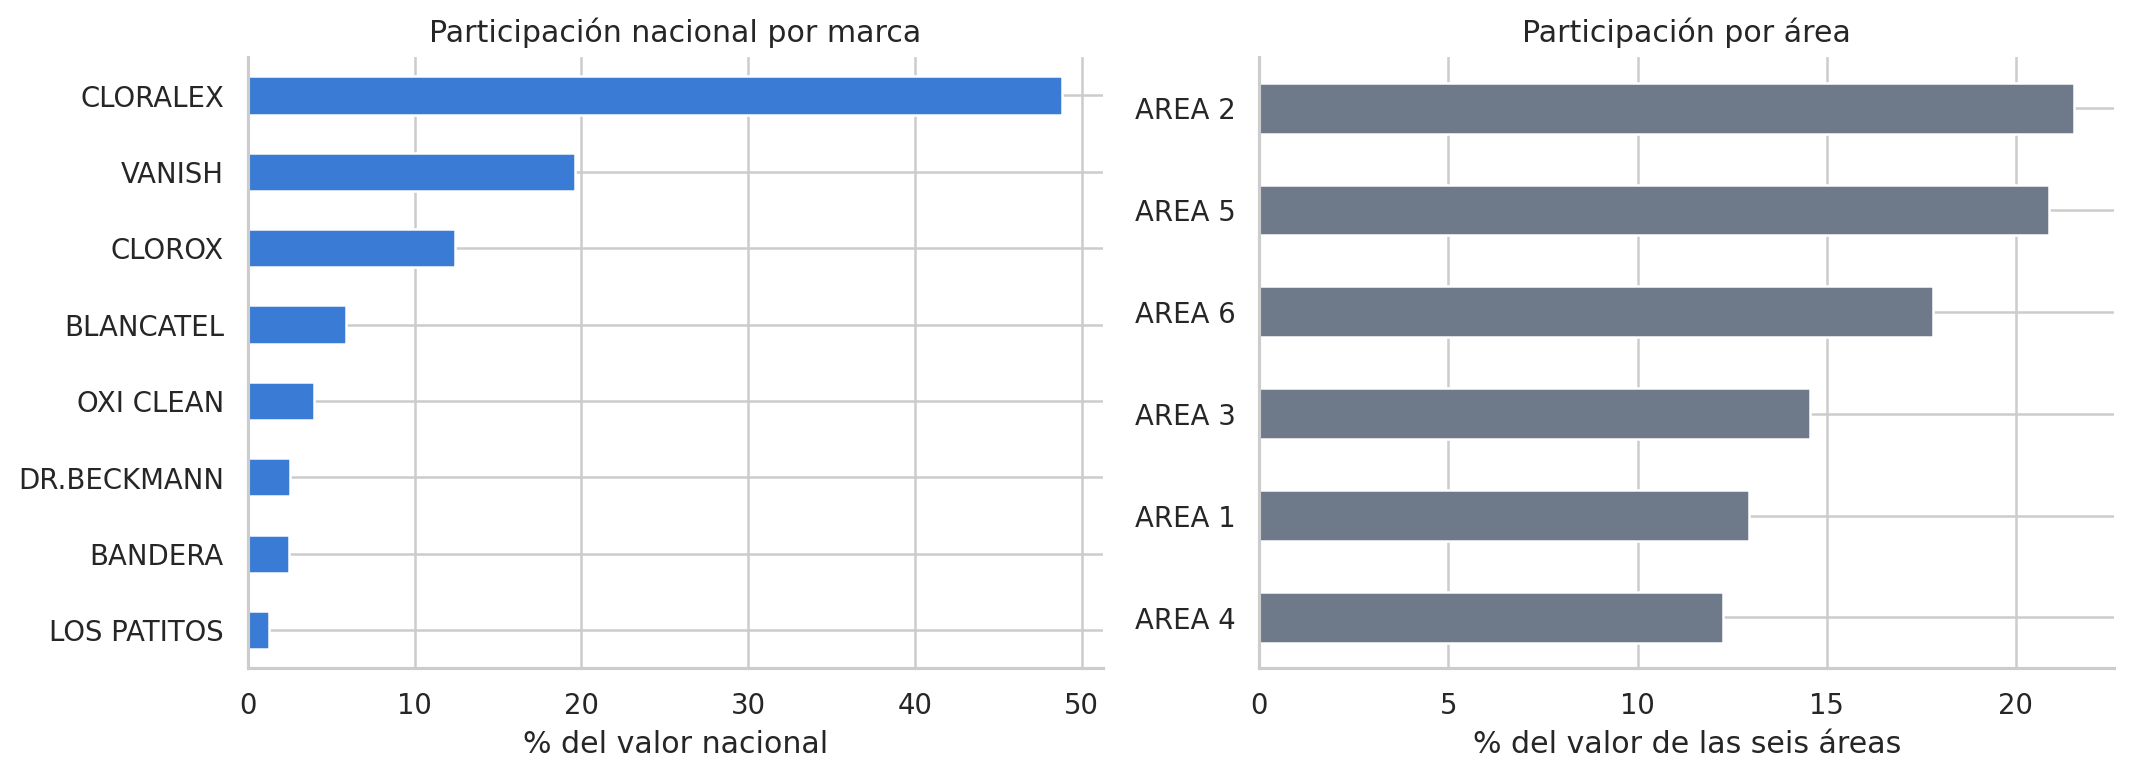

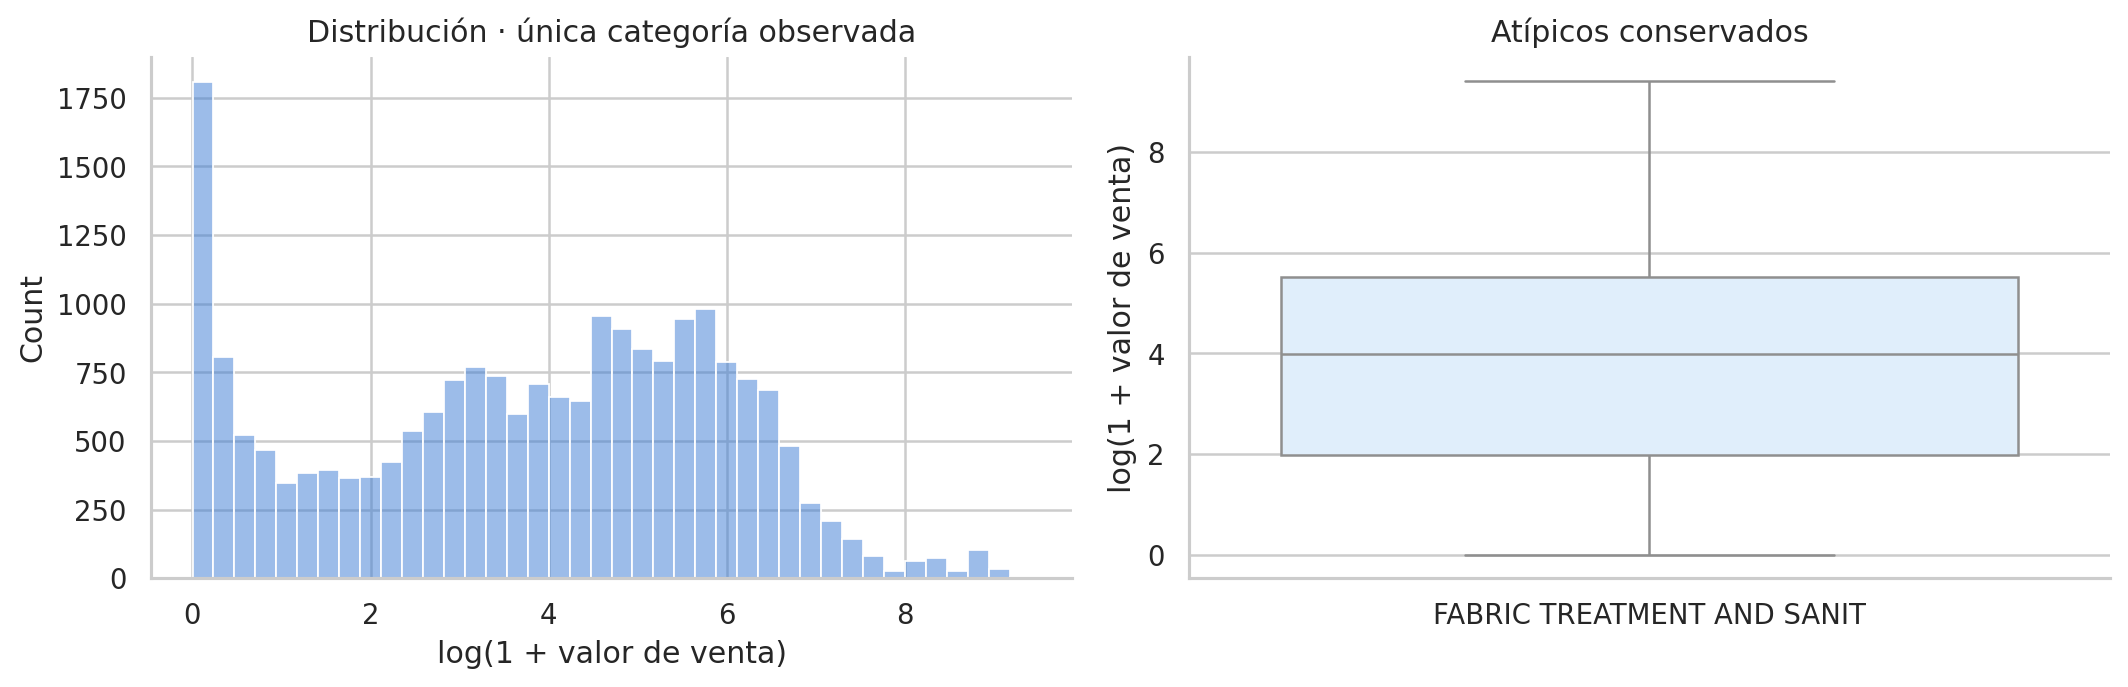

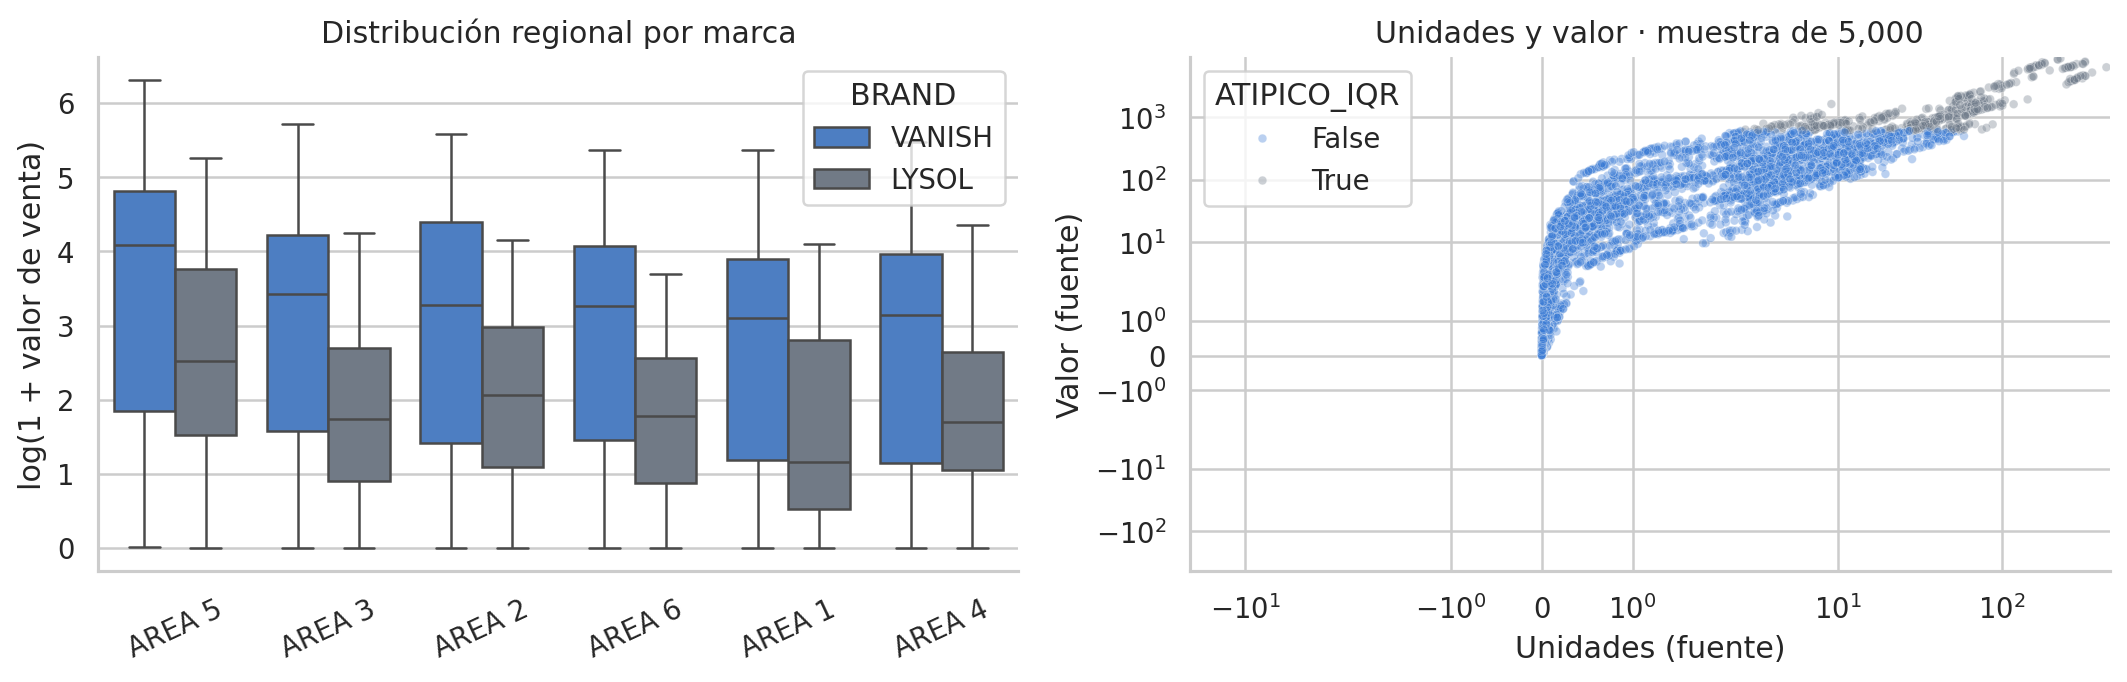

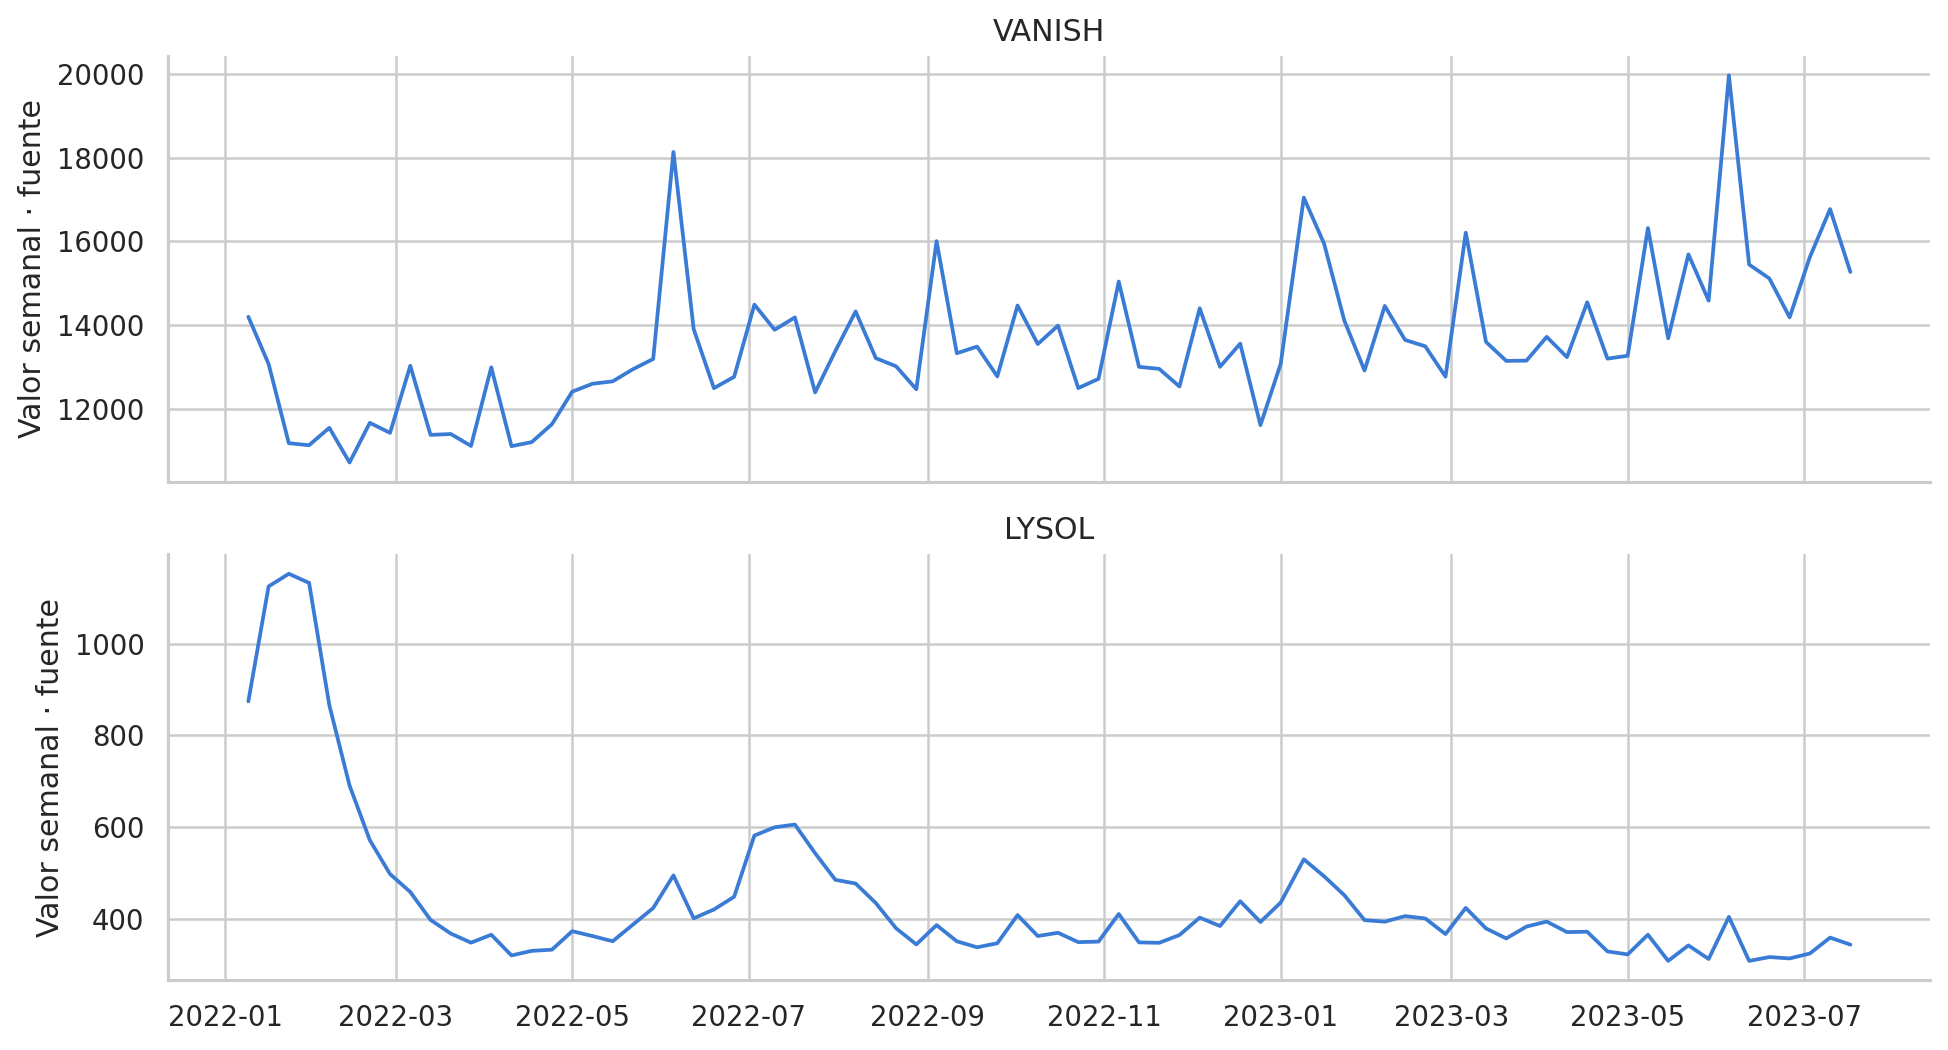

             valor  unidades  semanas  valor_medio_semanal
DATE                                                      
2022-01  273916.40  10493.21        4             68479.10
2022-02  247267.56   9462.33        4             61816.89
2022-03  255026.13   9353.94        4             63756.53
2022-04  261002.07   9413.44        4             65250.52
2022-05  337474.74  12119.18        5             67494.95
2022-06  301899.97  11390.44        4             75474.99
2022-07  351031.16  12829.68        5             70206.23
2022-08  272720.48  10168.62        4             68180.12
2022-09  280613.03  10343.96        4             70153.26
2022-10  334475.54  11839.87        5             66895.11
2022-11  263025.01   9153.86        4             65756.25
2022-12  260553.06   8909.57        4             65138.26
2023-01  357314.21  12289.72        5             71462.84
2023-02  261785.74   8772.54        4             65446.44
2023-03  270574.89   9068.32        4             67643.

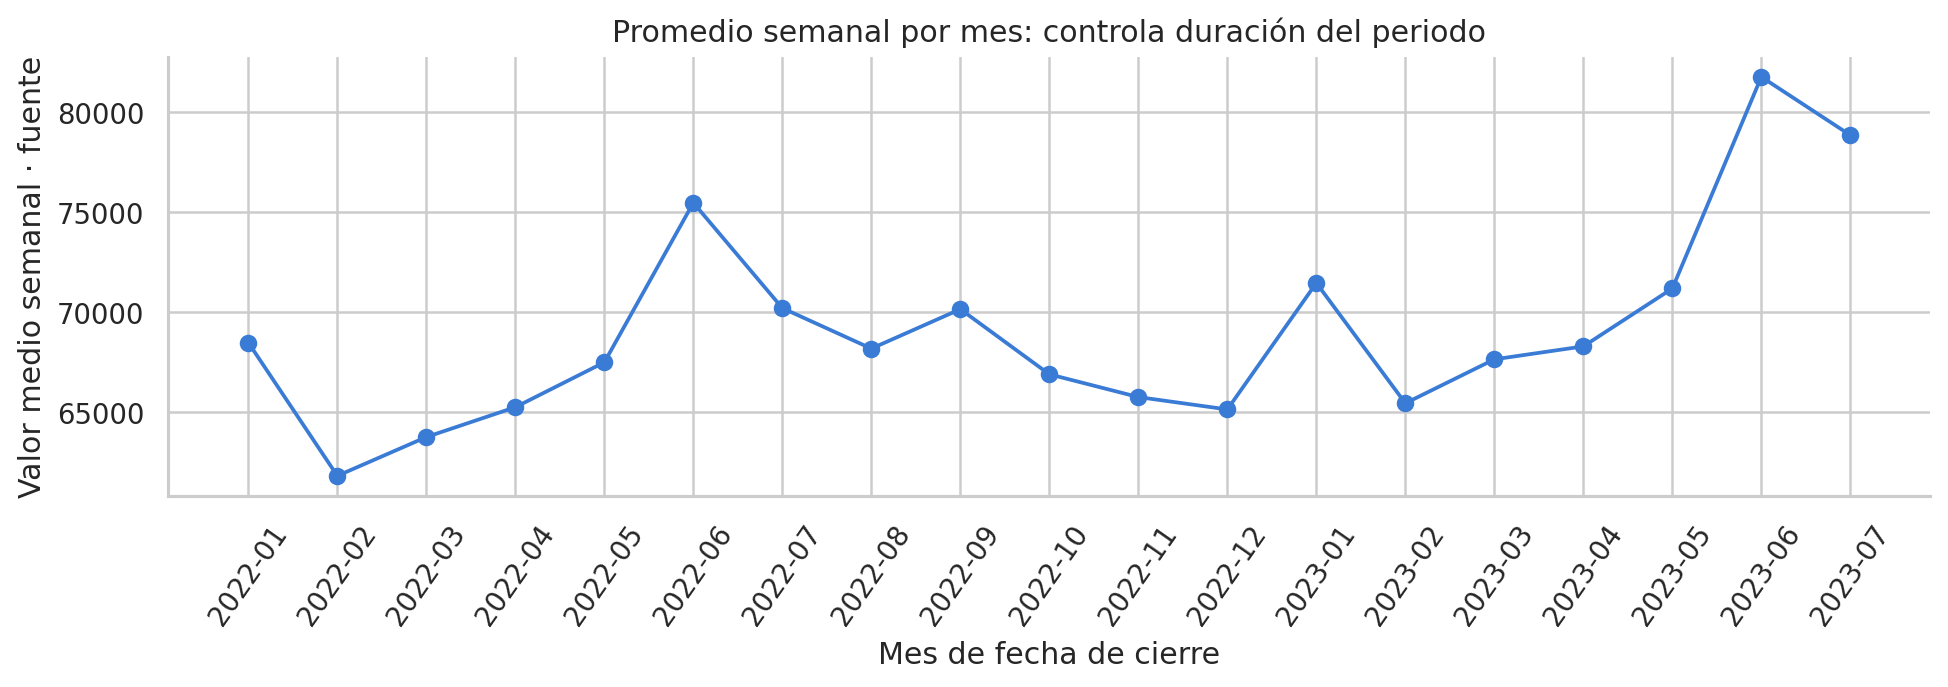

In [3]:
bybrand=mx.groupby('BRAND').TOTAL_VALUE_SALES.sum().sort_values(ascending=False)
byarea=a.groupby('REGION').TOTAL_VALUE_SALES.sum().sort_values(ascending=False)
byseg=mx.groupby('SEGMENT').TOTAL_VALUE_SALES.sum().sort_values(ascending=False)
display((bybrand/bybrand.sum()*100).head(10).to_frame('Participación nacional %').round(2))
display((byarea/byarea.sum()*100).to_frame('Participación áreas %').round(2))
display((byseg/byseg.sum()*100).to_frame('Participación segmento %').round(2))
fig,ax=plt.subplots(1,2,figsize=(12,4.5))
(bybrand.head(8)/bybrand.sum()*100).sort_values().plot.barh(ax=ax[0],color='#3A7BD5')
ax[0].set(title='Participación nacional por marca',xlabel='% del valor nacional',ylabel='')
(byarea/byarea.sum()*100).sort_values().rename(index=lambda x:x.replace('TOTAL AUTOS ','')).plot.barh(ax=ax[1],color='#6E7A89')
ax[1].set(title='Participación por área',xlabel='% del valor de las seis áreas',ylabel='')
finish('01_mercado_areas')
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.histplot(data=mx.assign(log_ventas=np.log1p(mx.TOTAL_VALUE_SALES)),x='log_ventas',hue='CATEGORY_NAME',bins=40,ax=ax[0],legend=False)
ax[0].set(title='Distribución · única categoría observada',xlabel='log(1 + valor de venta)')
sns.boxplot(data=mx.assign(log_ventas=np.log1p(mx.TOTAL_VALUE_SALES)),x='CATEGORY_NAME',y='log_ventas',ax=ax[1],color='#DCEEFF')
ax[1].set(title='Atípicos conservados',xlabel='',ylabel='log(1 + valor de venta)')
finish('02_distribucion')
focus=a[a.BRAND.isin(['VANISH','LYSOL'])].copy()
focus['AREA']=focus.REGION.str.replace('TOTAL AUTOS ','',regex=False)
focus['log_ventas']=np.log1p(focus.TOTAL_VALUE_SALES)
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.boxplot(data=focus,x='AREA',y='log_ventas',hue='BRAND',showfliers=True,ax=ax[0],fliersize=1)
ax[0].set(title='Distribución regional por marca',xlabel='',ylabel='log(1 + valor de venta)');ax[0].tick_params(axis='x',rotation=25)
q1,q3=mx.TOTAL_VALUE_SALES.quantile([.25,.75]); threshold=q3+1.5*(q3-q1)
mx['ATIPICO_IQR']=mx.TOTAL_VALUE_SALES>threshold
sample=mx.sample(min(5000,len(mx)),random_state=42)
sns.scatterplot(data=sample,x='TOTAL_UNIT_SALES',y='TOTAL_VALUE_SALES',hue='ATIPICO_IQR',alpha=.35,s=12,ax=ax[1])
ax[1].set(xscale='symlog',yscale='symlog',title='Unidades y valor · muestra de 5,000',xlabel='Unidades (fuente)',ylabel='Valor (fuente)')
finish('03_areas_atipicos')
print('Umbral IQR nacional:',round(threshold,3),'| Registros marcados:',int(mx.ATIPICO_IQR.sum()))
mx[mx.ATIPICO_IQR].to_csv(OUT/'atipicos_para_revision.csv',index=False)
fig,axes=plt.subplots(2,1,figsize=(11,6),sharex=True)
for ax,b in zip(axes,['VANISH','LYSOL']):
    ax.plot(weekly.index,weekly[b],color='#3A7BD5');ax.set(title=b,ylabel='Valor semanal · fuente')
finish('04_series_marcas')
monthly=(mx.groupby(mx.DATE.dt.to_period('M')).agg(valor=('TOTAL_VALUE_SALES','sum'),
         unidades=('TOTAL_UNIT_SALES','sum'),semanas=('WEEK','nunique')))
monthly['valor_medio_semanal']=monthly.valor/monthly.semanas
display(monthly.round(2));monthly.to_csv(OUT/'resumen_mensual.csv')
fig,ax=plt.subplots(figsize=(11,4));ax.plot(monthly.index.astype(str),monthly.valor_medio_semanal,marker='o')
ax.set(title='Promedio semanal por mes: controla duración del periodo',ylabel='Valor medio semanal · fuente',xlabel='Mes de fecha de cierre')
ax.tick_params(axis='x',rotation=55);finish('05_tendencia_mensual')
print('Advertencia: julio de 2023 contiene solo',monthly.iloc[-1].semanas,'semanas observadas.')

## 4. K-Means: continuidad, intensidad y precio implícito de Vanish
Se reproduce la metodología del entregable 3 sobre **77 productos VANISH** del agregado nacional. Se excluye del clustering un artículo con unidades acumuladas cero porque no permite calcular precio implícito; se conserva en el análisis de ventas.

Variables: unidades por semana observada, semanas con registros y valor/unidades. Precio implícito no representa un precio de lista ni permite comparar tamaños sin normalizar contenido. Se aplica log1p a intensidad y precio y StandardScaler a las tres variables. Codo y silueta evalúan k=2…8 con semilla 42 y 20 inicializaciones. Las semanas sin registro no se equiparan automáticamente a cero demanda.

k elegido: 4 | Excluidos: 1 | Fronterizos: 2


   k   Inercia  Silueta
0  2  138.0960   0.3872
1  3   82.3763   0.4463
2  4   48.2784   0.4934
3  5   38.8450   0.4753
4  6   30.8984   0.4586
5  7   25.6443   0.4431
6  8   22.2316   0.4520

                       productos  ...  participacion_valor_pct
SEGMENTO_KMEANS                   ...                         
ALTA ROTACION                 16  ...                   50.810
ALTO VALOR                    24  ...                   48.170
BAJA ROTACION ESTABLE         17  ...                    1.009
PRESENCIA MARGINAL            19  ...                    0.012

[4 rows x 7 columns]

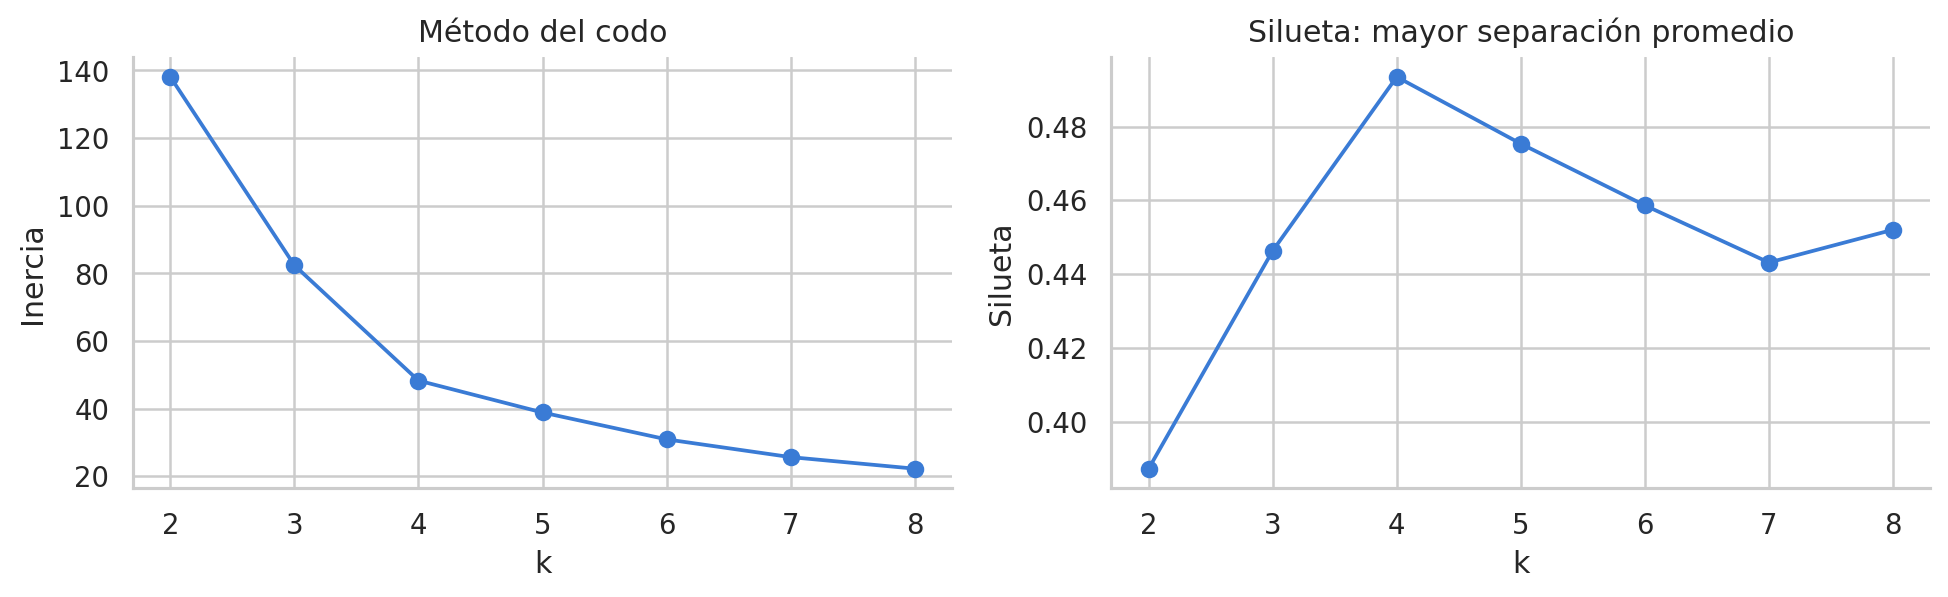

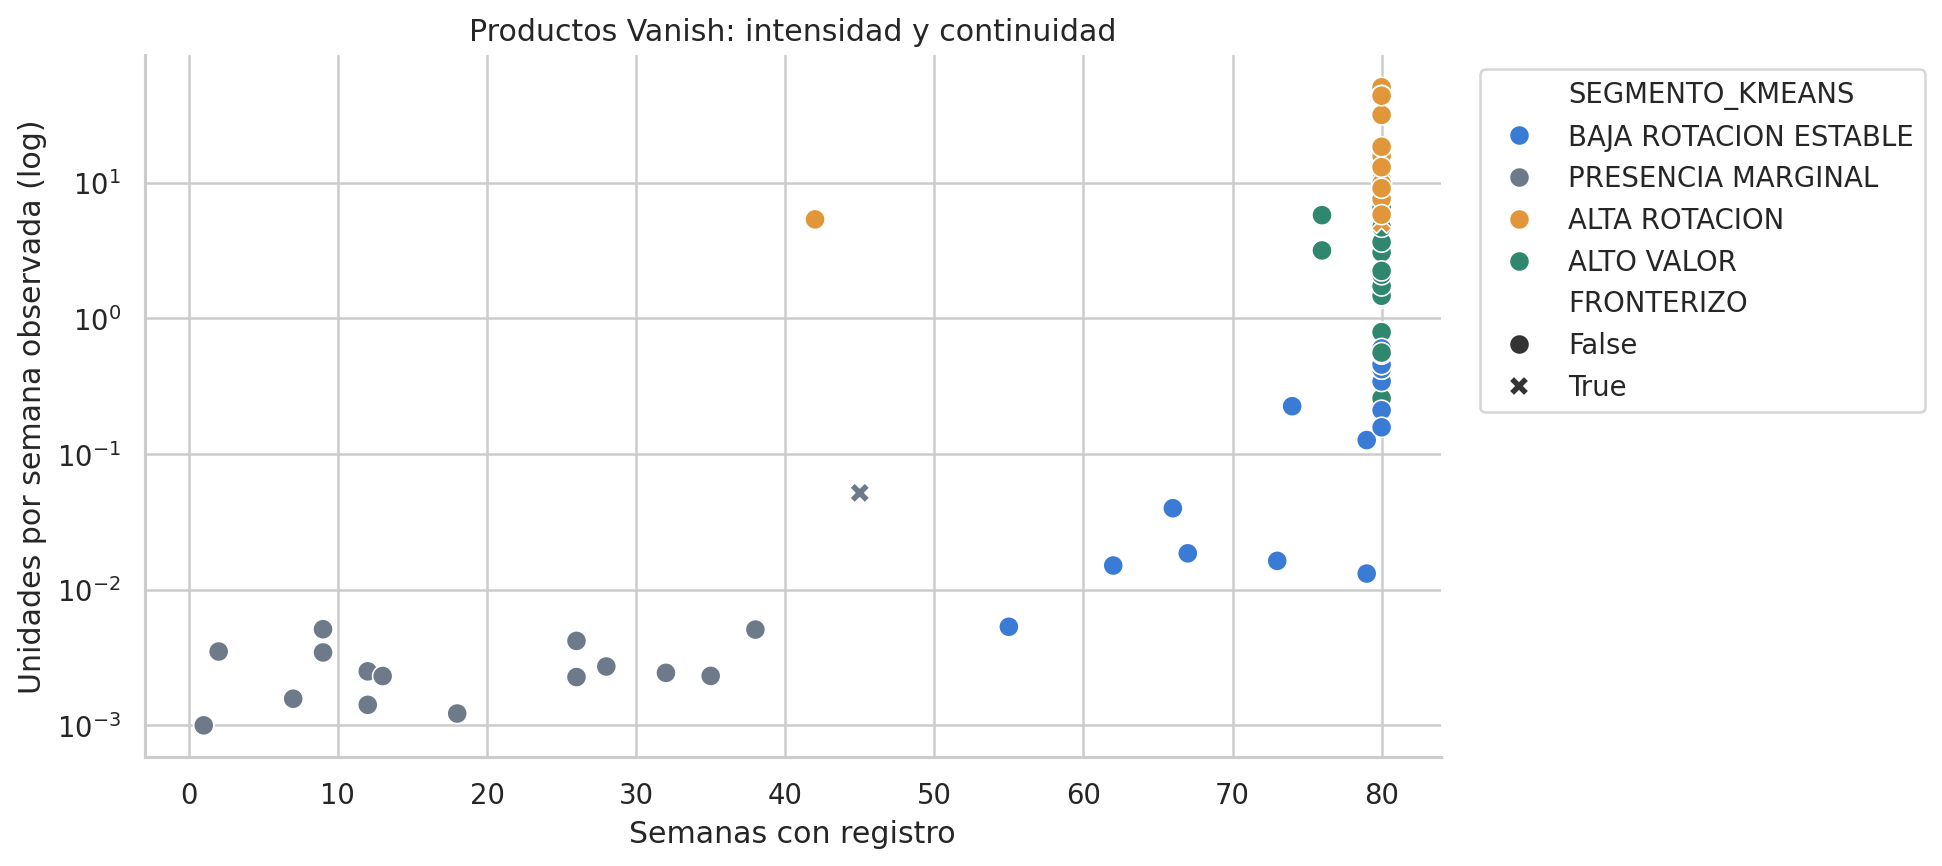

In [4]:
v=mx[mx.BRAND.eq('VANISH')]
z=v.groupby('ITEM_CODE',as_index=False).agg(VENTAS_UNIDADES=('TOTAL_UNIT_SALES','sum'),
    VENTAS_VALOR=('TOTAL_VALUE_SALES','sum'),SEMANAS_CON_VENTAS=('WEEK','nunique'))
z=z.merge(p[['ITEM','ITEM_DESCRIPTION','FORMAT']],left_on='ITEM_CODE',right_on='ITEM',validate='one_to_one')
z['UNIDADES_PROMEDIO_SEMANA']=z.VENTAS_UNIDADES/z.SEMANAS_CON_VENTAS
z['PRECIO_IMPLICITO']=z.VENTAS_VALOR/z.VENTAS_UNIDADES.replace(0,np.nan)
excluded=z[z.PRECIO_IMPLICITO.isna()].copy(); z=z[z.PRECIO_IMPLICITO.notna()].copy()
excluded.to_csv(OUT/'excluido_solo_clustering.csv',index=False)
X=np.column_stack([np.log1p(z.UNIDADES_PROMEDIO_SEMANA),z.SEMANAS_CON_VENTAS,np.log1p(z.PRECIO_IMPLICITO)])
scaler=StandardScaler();X=scaler.fit_transform(X)
fits={k:KMeans(n_clusters=k,random_state=42,n_init=20).fit(X) for k in range(2,9)}
ktable=pd.DataFrame([{'k':k,'Inercia':fit.inertia_,'Silueta':silhouette_score(X,fit.labels_)} for k,fit in fits.items()])
display(ktable.round(4));best_k=int(ktable.loc[ktable.Silueta.idxmax(),'k']);fit=fits[best_k]
z['CLUSTER']=fit.labels_;z['SILUETA']=silhouette_samples(X,fit.labels_)
# Nombres semánticos derivados de los perfiles, independientes del número arbitrario de etiqueta.
profile=z.groupby('CLUSTER')[['UNIDADES_PROMEDIO_SEMANA','SEMANAS_CON_VENTAS','PRECIO_IMPLICITO']].median()
marginal=profile.SEMANAS_CON_VENTAS.idxmin();rotation=profile.UNIDADES_PROMEDIO_SEMANA.idxmax()
remaining=[i for i in profile.index if i not in [marginal,rotation]]
high=max(remaining,key=lambda i:profile.loc[i,'PRECIO_IMPLICITO'])
names={marginal:'PRESENCIA MARGINAL',rotation:'ALTA ROTACION',high:'ALTO VALOR'}
for i in profile.index:names.setdefault(i,'BAJA ROTACION ESTABLE')
z['SEGMENTO_KMEANS']=z.CLUSTER.map(names)
z['FRONTERIZO']=z.SILUETA<0
summary=z.groupby('SEGMENTO_KMEANS').agg(productos=('ITEM_CODE','size'),valor=('VENTAS_VALOR','sum'),
    unidades_semana_mediana=('UNIDADES_PROMEDIO_SEMANA','median'),semanas_mediana=('SEMANAS_CON_VENTAS','median'),
    precio_mediano=('PRECIO_IMPLICITO','median'),silueta_media=('SILUETA','mean'))
summary['participacion_valor_pct']=100*summary.valor/z.VENTAS_VALOR.sum()
display(summary.round(3));print('k elegido:',best_k,'| Excluidos:',len(excluded),'| Fronterizos:',z.FRONTERIZO.sum())
z.to_csv(OUT/'segmentacion_vanish.csv',index=False);summary.to_csv(OUT/'resumen_clusters.csv');ktable.to_csv(OUT/'seleccion_k.csv',index=False)
fig,ax=plt.subplots(1,2,figsize=(11,3.5));ax[0].plot(ktable.k,ktable.Inercia,'o-');ax[0].set(title='Método del codo',xlabel='k',ylabel='Inercia')
ax[1].plot(ktable.k,ktable.Silueta,'o-');ax[1].set(title='Silueta: mayor separación promedio',xlabel='k',ylabel='Silueta');finish('06_seleccion_clusters')
fig,ax=plt.subplots(figsize=(11,5))
sns.scatterplot(data=z,x='SEMANAS_CON_VENTAS',y='UNIDADES_PROMEDIO_SEMANA',hue='SEGMENTO_KMEANS',style='FRONTERIZO',s=65,ax=ax)
ax.set(yscale='log',title='Productos Vanish: intensidad y continuidad',xlabel='Semanas con registro',ylabel='Unidades por semana observada (log)')
ax.legend(bbox_to_anchor=(1.02,1),loc='upper left');finish('07_clusters')

**Lectura de negocio:** alta rotación requiere asegurar disponibilidad; alto valor requiere revisar surtido y rentabilidad; baja rotación estable requiere evaluar productividad por SKU; presencia marginal requiere comprobar altas/bajas de catálogo y cobertura antes de retirar productos. Las etiquetas no miden rentabilidad y los casos con silueta negativa requieren revisión individual.

## 5. SQL Server: estructura, consultas y evidencia
La base y las consultas fueron ejecutadas en el entregable 4. El archivo `consultas_sql_server.sql` contiene el esquema y las consultas para reproducir las validaciones, el nacional, el ranking regional y la mezcla por segmento. Las capturas adjuntas son páginas originales de esa entrega; no se afirma una nueva ejecución de SQL Server en este entorno.

La suma de las siete etiquetas regionales duplica prácticamente el mercado, porque una de ellas es el agregado nacional. Para KPI nacional se filtra el agregado; para comparar áreas se excluye.

SELECT c.CATEGORY_NAME,
       SUM(f.TOTAL_VALUE_SALES) AS VENTAS_NACIONALES
FROM dbo.FACT_SALES AS f
JOIN dbo.DIM_PRODUCT AS p ON p.ITEM=f.ITEM_CODE
JOIN dbo.DIM_CATEGORY AS c ON c.ID_CATEGORY=p.CATEGORY
WHERE f.REGION=N'TOTAL AUTOS SCANNING MEXICO'
GROUP BY c.CATEGORY_NAME;



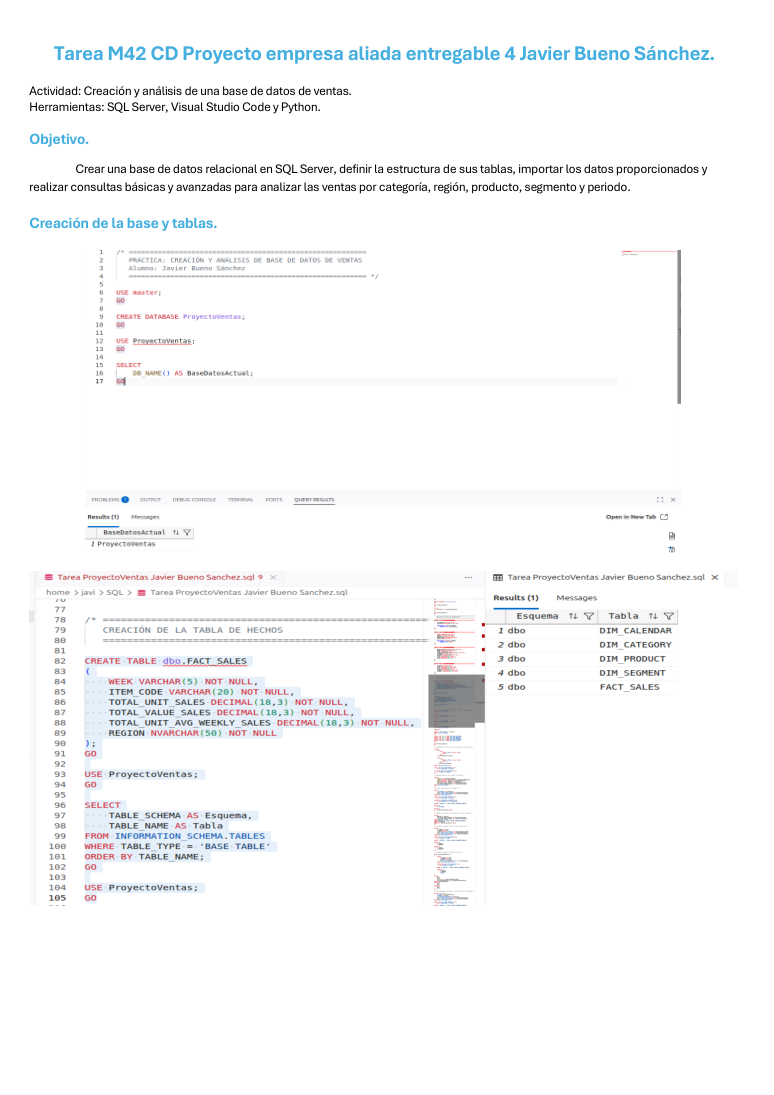

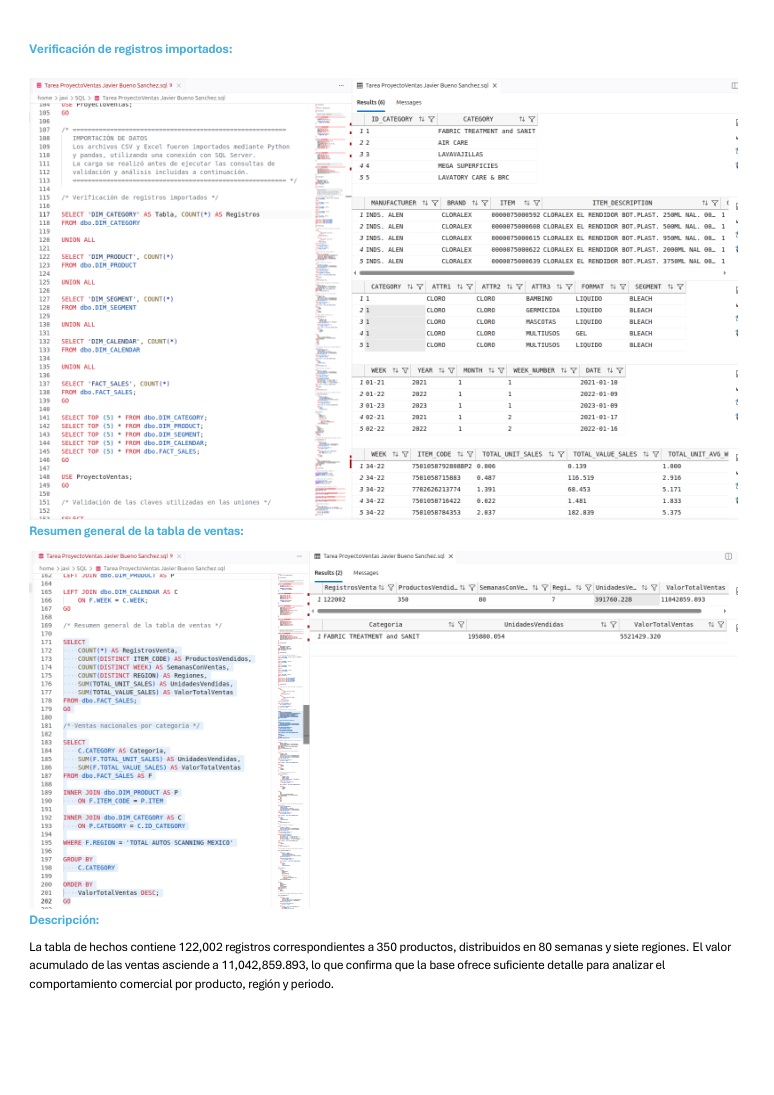

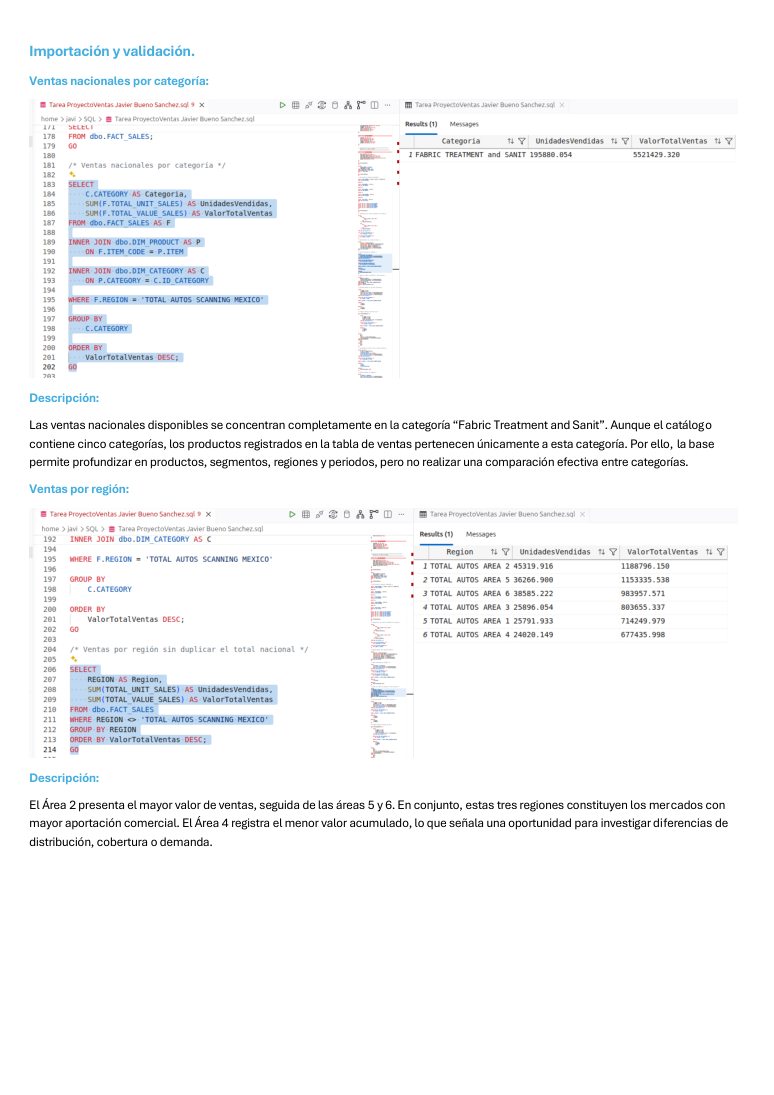

In [5]:
sql_ejemplo="""SELECT c.CATEGORY_NAME,
       SUM(f.TOTAL_VALUE_SALES) AS VENTAS_NACIONALES
FROM dbo.FACT_SALES AS f
JOIN dbo.DIM_PRODUCT AS p ON p.ITEM=f.ITEM_CODE
JOIN dbo.DIM_CATEGORY AS c ON c.ID_CATEGORY=p.CATEGORY
WHERE f.REGION=N'TOTAL AUTOS SCANNING MEXICO'
GROUP BY c.CATEGORY_NAME;
"""
print(sql_ejemplo)
for name in ['sql_page_1.png','sql_page_2.png','sql_page_3.png']:
    path=ROOT/'evidencias'/name
    if path.exists():display(Image(filename=str(path),width=850))

## 6. Power BI: informe interactivo y alcance geográfico
Se adjunta el PBIX existente con cuatro páginas: resumen nacional, productos y áreas, escenarios y mapa ilustrativo. Se verificó su definición interna: filtros separados para nacional y áreas, tarjetas, barras, líneas, tablas y segmentadores. Las capturas incorporadas documentan el estado visible de las páginas.

**Geografía:** la asignación Área 1→Quintana Roo, 2→Estado de México, 3→Querétaro, 4→Chihuahua, 5→Jalisco y 6→Michoacán es ilustrativa y definida para el ejercicio; no procede de una correspondencia territorial acreditada por la fuente. El mapa no se utiliza para inferir resultados estatales. La captura disponible del mapa muestra un bloqueo de configuración del servicio. No se dispone de enlace publicado confirmado.

**Escenarios:** los parámetros de escenario del PBIX no sustituyen los pronósticos estadísticos validados de la siguiente sección.

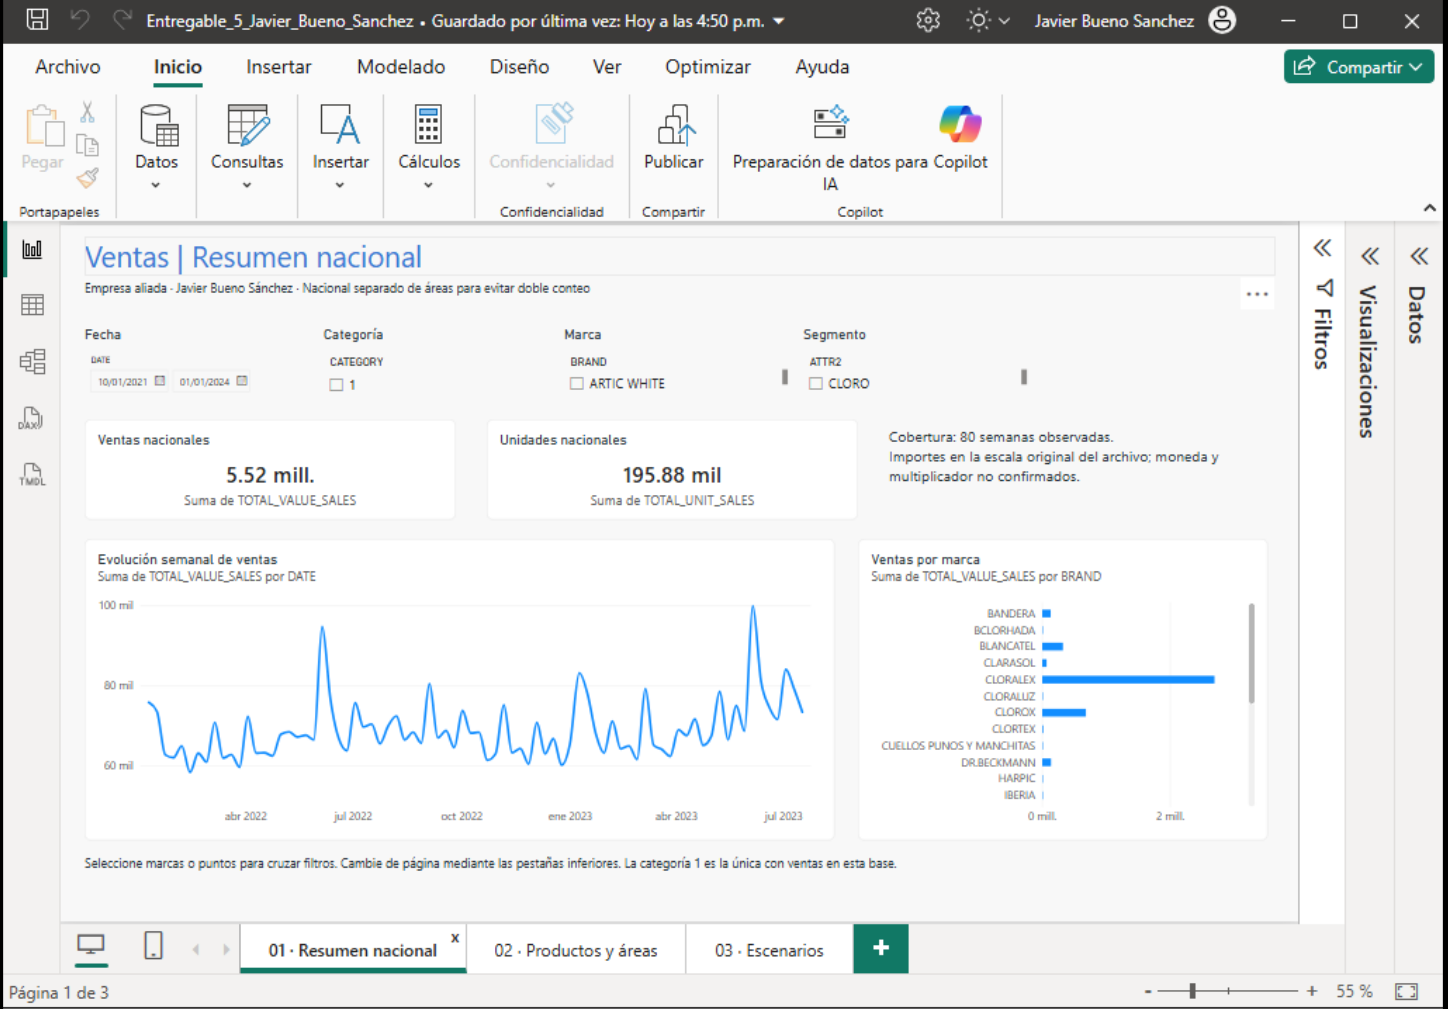

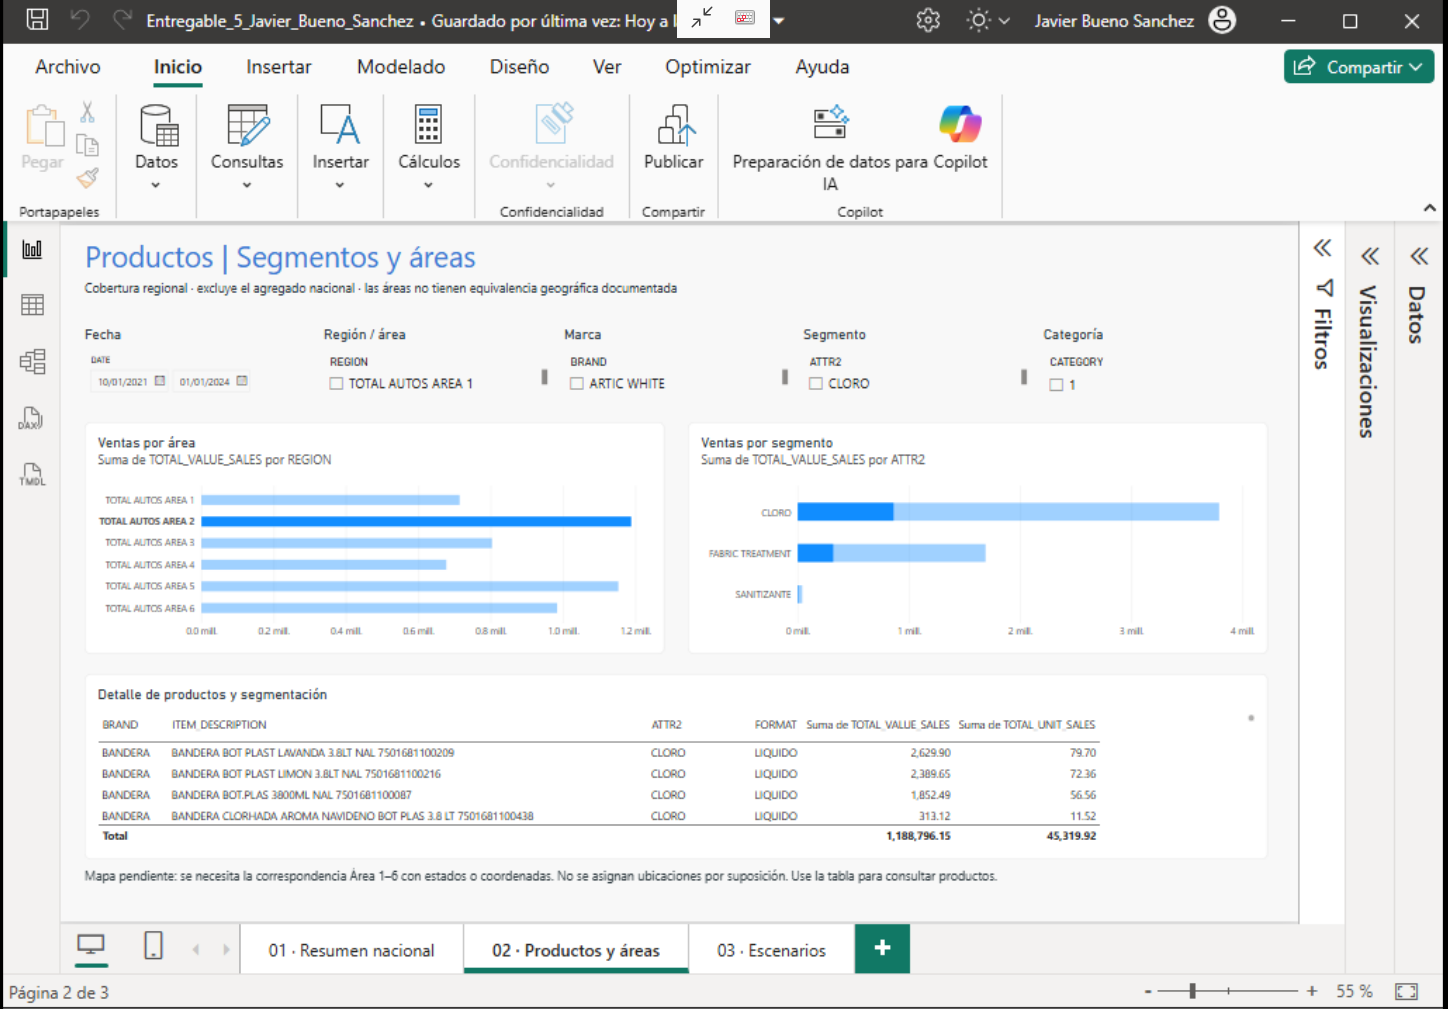

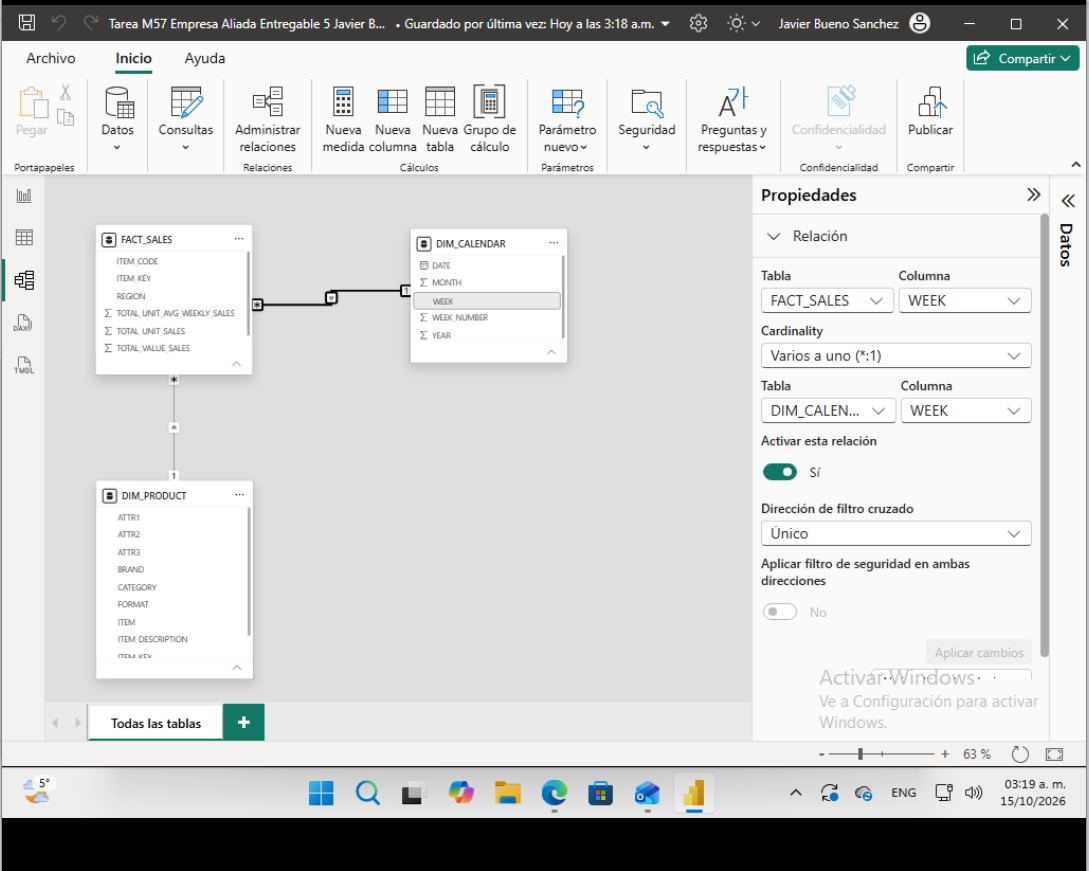

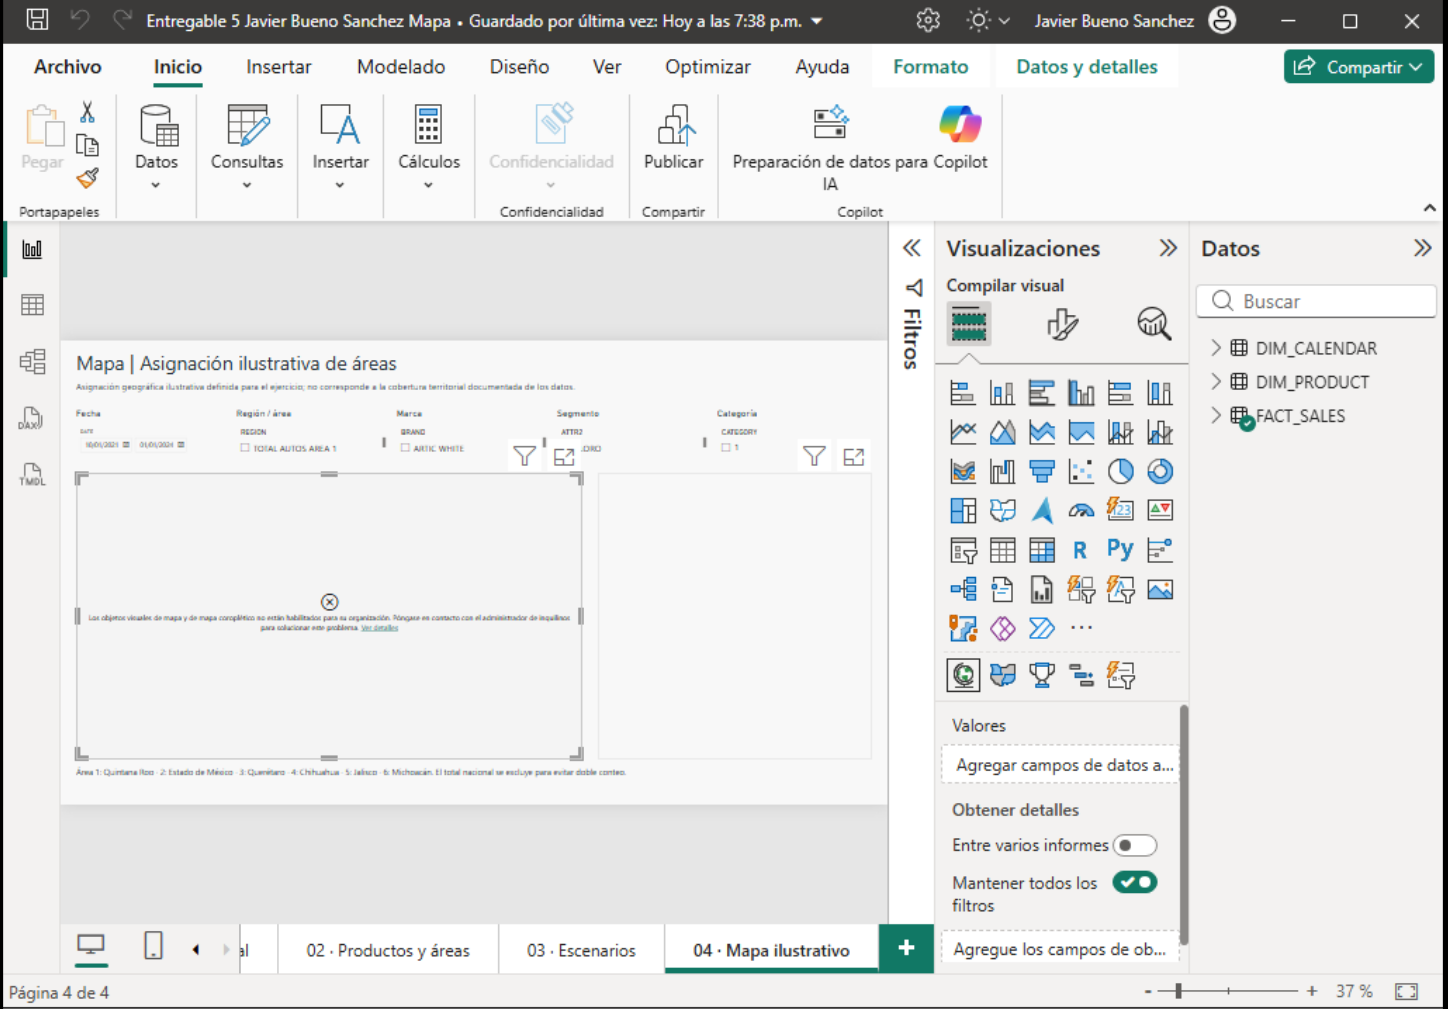

In [6]:
for name in ['powerbi_resumen.png','powerbi_productos.png','powerbi_modelo.png','powerbi_mapa.png']:
    path=ROOT/'evidencias'/name
    if path.exists():display(Image(filename=str(path),width=1000))

## 7. Pronóstico de ventas: regresión múltiple, ARIMA y referencias
**Objetivo:** valor nacional semanal de las etiquetas exactas VANISH y LYSOL. Se usan 80 observaciones ordenadas por fecha, de enero de 2022 a julio de 2023. La fuente cambia el cierre de domingo a lunes; se conserva el orden semanal y no se inventan días de venta.

**División cronológica sin fuga:** primeras 56 semanas para entrenamiento, siguientes 12 para selección y últimas 12 para prueba final. La elección del método se fija con el MAE de validación. Después se ajusta con 68 semanas y se evalúa una única vez en prueba. No se cambia el ganador por sus resultados de prueba.

**Candidatos:** regresión lineal múltiple con tendencia y términos seno/coseno anual (52 observaciones), ARIMA(p,d,q) con p,q=0…2 y d=0,1 (excepto p=q=2), última semana y media de cuatro semanas. Se excluyen ARIMA que no converjan. Todos reciben el mismo horizonte de validación de 12 semanas. No hay covariables futuras de precio, promociones o inventario.

Con 80 semanas, la estacionalidad anual tiene poca evidencia: los términos armónicos son un candidato, no una conclusión. Se reportan MAE, MSE, RMSE, MAPE y sesgo; MSE usa unidades al cuadrado.

Ajustes descartados: 0


     Marca          Modelo  ... MAPE_pct Sesgo_pred_menos_real
31   LYSOL  ARIMA(0, 1, 1)  ...    5.049                 2.224
32   LYSOL  ARIMA(0, 1, 2)  ...    5.501                 7.102
19   LYSOL   Ultima semana  ...    6.086                15.759
30   LYSOL  ARIMA(0, 1, 0)  ...    6.086                15.759
33   LYSOL  ARIMA(1, 1, 0)  ...    6.661               -21.175
8   VANISH  ARIMA(1, 0, 2)  ...    3.975              -382.567
17  VANISH  ARIMA(2, 1, 0)  ...    4.105              -126.954
14  VANISH  ARIMA(1, 1, 0)  ...    4.641              -622.481
3   VANISH  ARIMA(0, 0, 0)  ...    4.937              -671.343
15  VANISH  ARIMA(1, 1, 1)  ...    5.150                90.338

[10 rows x 9 columns]

    Marca              Modelo  ...  MAPE_pct  Sesgo_pred_menos_real
0  VANISH       Ultima semana  ...    13.942              -2299.022
1  VANISH     Media 4 semanas  ...    11.349              -1822.895
2  VANISH  Regresion multiple  ...     6.970               -707.919
3  VANISH      ARIMA(1, 0, 2)  ...    12.868              -2104.192
4   LYSOL       Ultima semana  ...     6.294                 -6.125
5   LYSOL     Media 4 semanas  ...    11.565                 31.336
6   LYSOL  Regresion multiple  ...    54.040               -182.738
7   LYSOL      ARIMA(0, 1, 1)  ...     6.129                -18.178

[8 rows x 8 columns]

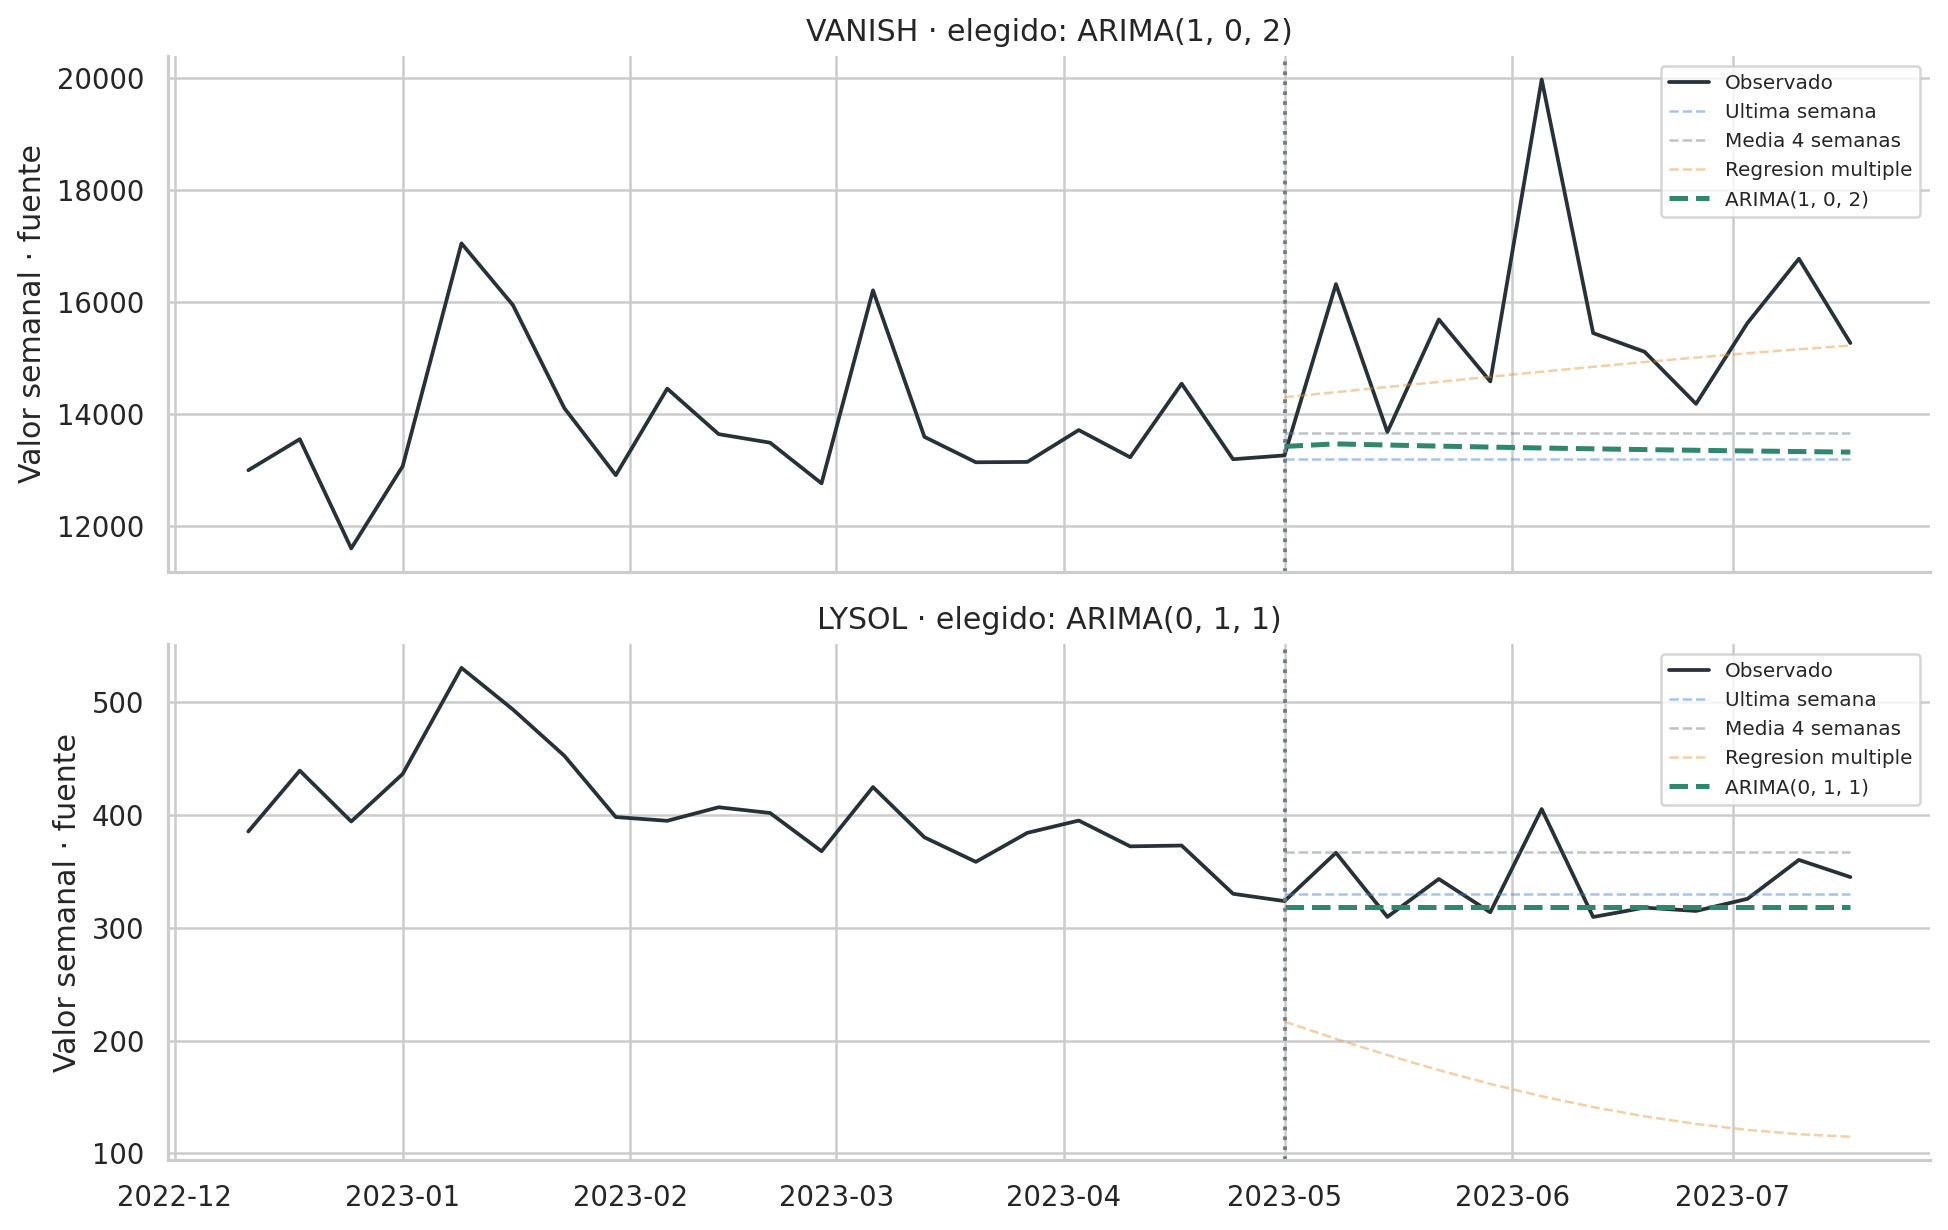

In [7]:
def features(indices):
    x=np.asarray(indices,dtype=float)
    return np.column_stack([x/52,np.sin(2*np.pi*x/52),np.cos(2*np.pi*x/52)])

def predict_method(y,h,method,order=None):
    y=np.asarray(y,float)
    if method=='Ultima semana':return np.repeat(y[-1],h),None
    if method=='Media 4 semanas':return np.repeat(y[-4:].mean(),h),None
    if method=='Regresion multiple':
        fit=LinearRegression().fit(features(np.arange(len(y))),y)
        return np.maximum(fit.predict(features(np.arange(len(y),len(y)+h))),0),fit
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        fit=ARIMA(y,order=order,trend='c' if order[1]==0 else 'n',
                  enforce_stationarity=True,enforce_invertibility=True).fit()
    if not fit.mle_retvals.get('converged',True):raise ValueError('ARIMA no convergente')
    return np.maximum(np.asarray(fit.forecast(h)),0),fit

def score(real,pred):
    real=np.asarray(real); pred=np.asarray(pred); err=pred-real
    return {'MAE':float(np.mean(np.abs(err))),'MSE':float(np.mean(err**2)),
            'RMSE':float(np.sqrt(np.mean(err**2))),'MAPE_pct':float(100*np.mean(np.abs(err/real))),
            'Sesgo_pred_menos_real':float(np.mean(err))}

orders=[(p0,d0,q0) for d0 in [0,1] for p0 in range(3) for q0 in range(3) if not(p0==q0==2)]
valid_rows=[]; test_rows=[]; evaluations={}; failed=[]
for brand in ['VANISH','LYSOL']:
    y=weekly[brand].to_numpy();assert np.isfinite(y).all() and (y>0).all()
    train,valid,test=y[:56],y[56:68],y[68:]
    pool=[(m,None) for m in ['Ultima semana','Media 4 semanas','Regresion multiple']]+[('ARIMA',o) for o in orders]
    records=[]
    for method,order in pool:
        try:
            pred,fit0=predict_method(train,12,method,order)
            name=method if order is None else f'ARIMA{order}'
            row={'Marca':brand,'Modelo':name,'Metodo':method,'Orden':str(order),**score(valid,pred)}
            records.append((row,method,order));valid_rows.append(row)
        except (ValueError,np.linalg.LinAlgError) as e:failed.append({'Marca':brand,'Metodo':method,'Orden':str(order),'Motivo':str(e)})
    best=min(records,key=lambda r:r[0]['MAE']);chosen=best[0]['Modelo']
    # Tabla final: mejor ARIMA de validación, regresión y ambas referencias.
    best_arima=min([r for r in records if r[1]=='ARIMA'],key=lambda r:r[0]['MAE'])
    comparison=[r for r in records if r[1]!='ARIMA']+[best_arima]
    test_preds={}
    for row,method,order in comparison:
        pred,fit0=predict_method(y[:68],12,method,order)
        test_preds[row['Modelo']]=pred
        test_rows.append({'Marca':brand,'Modelo':row['Modelo'],'Elegido_en_validacion':row['Modelo']==chosen,**score(test,pred)})
    evaluations[brand]={'chosen':chosen,'method':best[1],'order':best[2],
                         'valid_MAE':best[0]['MAE'],'test_pred':test_preds[chosen],'test_preds':test_preds}
valid_metrics=pd.DataFrame(valid_rows);test_metrics=pd.DataFrame(test_rows)
display(valid_metrics.sort_values(['Marca','MAE']).groupby('Marca').head(5).round(3))
display(test_metrics.round(3));print('Ajustes descartados:',len(failed))
valid_metrics.to_csv(OUT/'metricas_validacion.csv',index=False);test_metrics.to_csv(OUT/'metricas_prueba.csv',index=False)
pd.DataFrame(failed).to_csv(OUT/'arima_descartados.csv',index=False)
fig,axes=plt.subplots(2,1,figsize=(11,7),sharex=True)
for ax,(brand,ev) in zip(axes,evaluations.items()):
    ax.plot(weekly.index[-32:],weekly[brand].iloc[-32:],label='Observado',color='#263238')
    for name,pred in ev['test_preds'].items():
        ax.plot(weekly.index[-12:],pred,ls='--',lw=2 if name==ev['chosen'] else 1,alpha=1 if name==ev['chosen'] else .45,label=name)
    ax.axvline(weekly.index[68],ls=':',color='#6E7A89');ax.set(title=f"{brand} · elegido: {ev['chosen']}",ylabel='Valor semanal · fuente');ax.legend(fontsize=8)
finish('08_prueba_modelos')

### Diagnóstico y pronóstico futuro
Se revisa sesgo de prueba y autocorrelación de residuos del ARIMA finalista. Una prueba Ljung-Box favorable no garantiza que todos los supuestos se cumplan. La regresión es predictiva y no causal.

Se reentrena el método elegido con las 80 semanas y se pronostican 15 semanas desde el último cierre, hasta octubre de 2023. Los rangos son **orientativos**, construidos con el percentil 90 del error absoluto de las 12 semanas de prueba; no tienen cobertura estadística garantizada ni ajustan su amplitud al horizonte. No se suman límites semanales para presentar intervalos mensuales.

Los totales mensuales agrupan por fecha de cierre: agosto y septiembre tienen cuatro semanas y octubre cinco. Una cifra mensual mayor por cinco semanas no implica crecimiento del ritmo de ventas. Julio pronosticado es parcial.

Out[8]: 7080


    Marca ARIMA_finalista  Ljung_Box_p_lag8
0  VANISH  ARIMA(1, 0, 2)          0.014659
1   LYSOL  ARIMA(0, 1, 1)          0.292572

    Marca  Intercepto  Tendencia_t_52  Seno_52  Coseno_52
0  VANISH   12200.736        1711.880 -294.102   -390.625
1   LYSOL     625.768        -272.848  -18.037     99.589

    Marca      Mes  Pronostico  Semanas  Promedio_semanal
0   LYSOL  2023-07      682.00        2            341.00
1   LYSOL  2023-08     1364.00        4            341.00
2   LYSOL  2023-09     1364.00        4            341.00
3   LYSOL  2023-10     1705.00        5            341.00
4  VANISH  2023-07    30331.07        2          15165.54
5  VANISH  2023-08    59887.15        4          14971.79
6  VANISH  2023-09    58981.30        4          14745.33
7  VANISH  2023-10    72671.10        5          14534.22

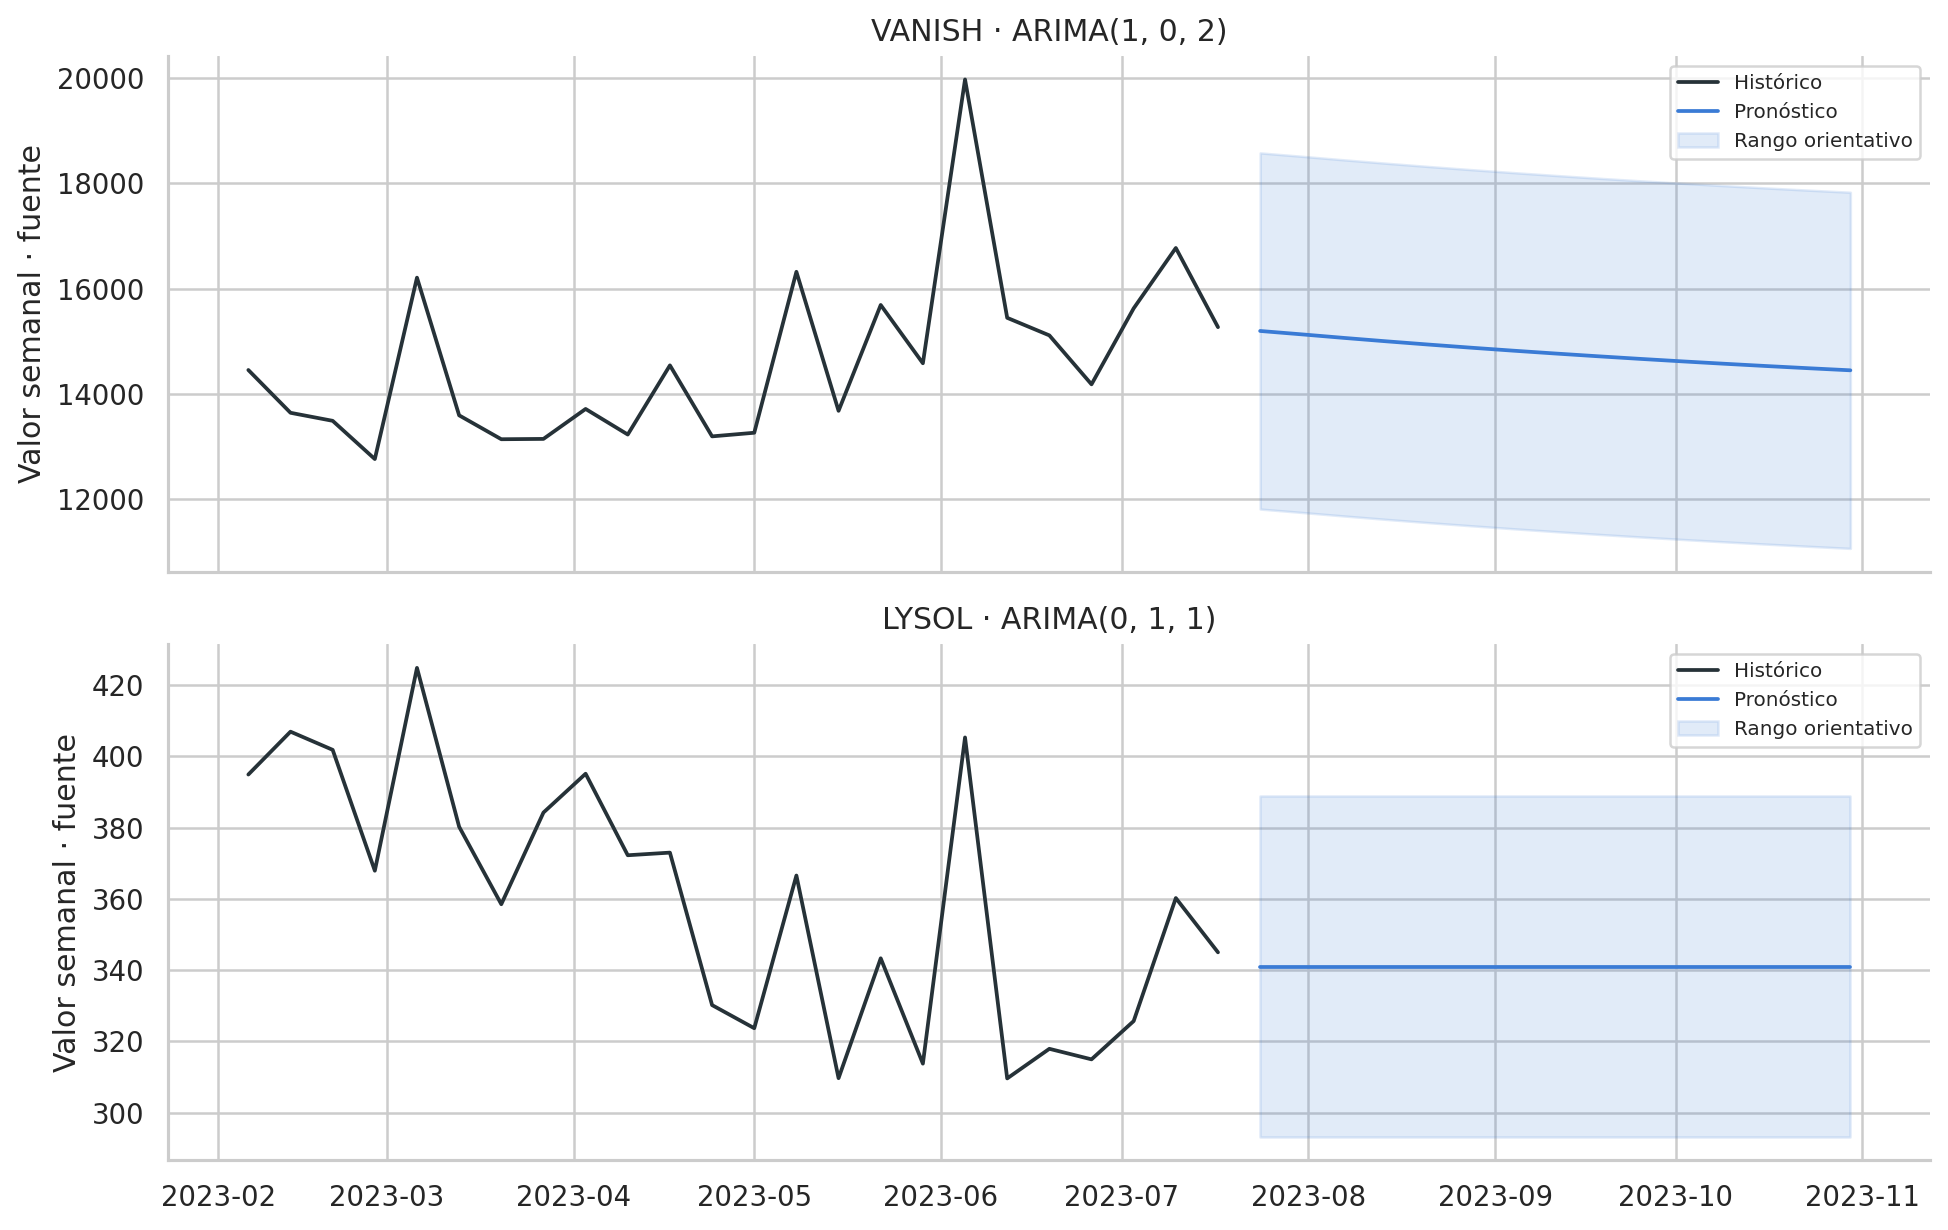

In [8]:
future_dates=pd.date_range(weekly.index[-1]+pd.Timedelta(days=7),periods=15,freq='7D')
forecast_rows=[];diagnostics=[];coefficients=[]
for brand,ev in evaluations.items():
    y=weekly[brand].to_numpy();pred,fit_final=predict_method(y,15,ev['method'],ev['order'])
    margin=float(np.quantile(np.abs(y[68:]-ev['test_pred']),.9))
    for date,value in zip(future_dates,pred):
        forecast_rows.append({'Marca':brand,'Fecha_cierre':date,'Modelo':ev['chosen'],'Pronostico':value,
            'Rango_inferior_orientativo':max(0,value-margin),'Rango_superior_orientativo':value+margin})
    arima_row=valid_metrics[(valid_metrics.Marca==brand)&(valid_metrics.Metodo=='ARIMA')].sort_values('MAE').iloc[0]
    import ast
    _,arfit=predict_method(y[:68],12,'ARIMA',ast.literal_eval(arima_row.Orden))
    lb=acorr_ljungbox(np.asarray(arfit.resid)[5:],lags=[8],model_df=sum(ast.literal_eval(arima_row.Orden)[::2]),return_df=True)
    diagnostics.append({'Marca':brand,'ARIMA_finalista':arima_row.Modelo,'Ljung_Box_p_lag8':float(lb.lb_pvalue.iloc[0])})
    _,reg=predict_method(y[:68],12,'Regresion multiple')
    coefficients.append({'Marca':brand,'Intercepto':reg.intercept_,'Tendencia_t_52':reg.coef_[0],
        'Seno_52':reg.coef_[1],'Coseno_52':reg.coef_[2]})
forecast=pd.DataFrame(forecast_rows);display(pd.DataFrame(diagnostics));display(pd.DataFrame(coefficients).round(3))
forecast['Mes']=forecast.Fecha_cierre.dt.to_period('M').astype(str)
future_monthly=forecast.groupby(['Marca','Mes'],as_index=False).agg(Pronostico=('Pronostico','sum'),Semanas=('Fecha_cierre','size'))
future_monthly['Promedio_semanal']=future_monthly.Pronostico/future_monthly.Semanas
display(future_monthly.round(2));forecast.to_csv(OUT/'pronostico_15_semanas.csv',index=False)
future_monthly.to_csv(OUT/'pronostico_mensual.csv',index=False)
pd.DataFrame(diagnostics).to_csv(OUT/'diagnostico_arima.csv',index=False)
pd.DataFrame(coefficients).to_csv(OUT/'coeficientes_regresion.csv',index=False)
fig,axes=plt.subplots(2,1,figsize=(11,7),sharex=True)
for ax,(brand,ev) in zip(axes,evaluations.items()):
    sub=forecast[forecast.Marca==brand]
    ax.plot(weekly.index[-24:],weekly[brand].iloc[-24:],label='Histórico',color='#263238')
    ax.plot(sub.Fecha_cierre,sub.Pronostico,label='Pronóstico',color='#3A7BD5')
    ax.fill_between(sub.Fecha_cierre,sub.Rango_inferior_orientativo,sub.Rango_superior_orientativo,alpha=.15,color='#3A7BD5',label='Rango orientativo')
    ax.set(title=f"{brand} · {ev['chosen']}",ylabel='Valor semanal · fuente');ax.legend(fontsize=8)
finish('09_pronostico')
# Resumen de resultados para la presentación; cifras calculadas, no transcritas a mano.
report={'filas':len(f),'productos_catalogo_validos':len(p),'productos_observados':mx.ITEM_CODE.nunique(),
 'semanas':len(weekly),'inicio':str(mx.DATE.min().date()),'fin':str(mx.DATE.max().date()),
 'nacional_valor':float(mx.TOTAL_VALUE_SALES.sum()),'nacional_unidades':float(mx.TOTAL_UNIT_SALES.sum()),
 'vanish_valor':float(bybrand['VANISH']),'lysol_valor':float(bybrand['LYSOL']),
 'marcas_pct':(100*bybrand/bybrand.sum()).to_dict(),'areas_pct':(100*byarea/byarea.sum()).to_dict(),
 'segmentos_pct':(100*byseg/byseg.sum()).to_dict(),'k':best_k,'silueta':float(ktable.Silueta.max()),
 'clusters':summary.reset_index().to_dict('records'),'fronterizos':int(z.FRONTERIZO.sum()),
 'elegidos':{b:{'Modelo':e['chosen'],'MAE_validacion':e['valid_MAE']} for b,e in evaluations.items()},
 'prueba':test_metrics.to_dict('records'),'pronostico_mensual':future_monthly.to_dict('records')}
(OUT/'resumen_ejecutivo.json').write_text(json.dumps(report,ensure_ascii=False,indent=2))

## 8. Conclusiones, impacto y próximos pasos
1. **Calidad y alcance:** los 122,002 registros conservan su trazabilidad; el agregado nacional y las áreas se separan. Las cinco categorías del catálogo no equivalen a cinco categorías con ventas.
2. **Priorización comercial:** el ranking por área y la concentración por marca/segmento permiten orientar revisiones de surtido y distribución. Los datos no incluyen costos, márgenes, inventario ni cobertura de tiendas; no prueban rentabilidad ni explican causas.
3. **Segmentación:** cuatro perfiles de Vanish permiten distinguir intensidad, continuidad y precio implícito. Revisar los productos fronterizos y la presencia marginal antes de cambiar el portafolio.
4. **Pronóstico:** el método se elige por MAE de validación y se contrasta con prueba cronológica independiente. Mantener una referencia simple evita asumir que un modelo complejo siempre mejora la decisión. Los resultados son un ejercicio histórico desde 2023.
5. **Decisión propuesta:** implementar una revisión semanal por marca y producto que combine pronóstico, error, existencias y tiempos de reposición. El pronóstico de valor no se transforma directamente en pedidos de unidades.
6. **Mejoras:** incorporar precios y promociones, unidades por SKU, stock, cobertura y costos; ampliar el histórico; usar validación de origen móvil; evaluar intervalos calibrados por horizonte; documentar territorios reales; completar la visualización del mapa y confirmar publicación de Power BI.

### Evidencia y límites
Las capturas SQL documentan el entregable 4 original. Las de Power BI documentan el estado real del informe, con las limitaciones señaladas. No se fabrica un mapa funcional ni un enlace de publicación. El paquete incluye datos originales, código, gráficos, resultados y PBIX para auditoría y reproducción.

### Resultados concretos y decisión de uso
- Valor nacional acumulado: **5,521,429.320** unidades originales de valor. Cloralex concentra 48.84%, Vanish 19.64% y Lysol 0.64% del universo observado.
- Las áreas 2, 5 y 6 aportan conjuntamente **60.24%** del valor de las áreas. Bleach concentra **68.65%** del nacional.
- K-Means reproduce **k=4**, silueta **0.4934** y perfiles de 16, 24, 17 y 19 productos. Alta rotación y alto valor aportan 98.98% del valor segmentado. Dos casos son fronterizos y un SKU quedó excluido solo del clustering.
- **Vanish:** ARIMA(1,0,2) gana en validación (MAE 585.08). En prueba, su MAE sube a 2,130.90 y la regresión obtiene 1,166.72. El ranking no es estable entre periodos.
- **Lysol:** ARIMA(0,1,1) gana en validación (MAE 18.90). En prueba, obtiene MAE 22.31 frente a 22.13 de la última semana. La mejora de complejidad no se confirma.
- Se conservan los métodos elegidos antes de prueba para generar la proyección académica. **No hay evidencia suficiente para automatizar pedidos.** Antes de cambiar la selección se requiere nueva validación de origen móvil, sin reutilizar este bloque de prueba como selección.
- La evaluación cubre 12 semanas, mientras que el pronóstico alcanza 15. Las últimas tres semanas requieren cautela adicional. Evaluar 16 configuraciones ARIMA sobre una validación corta también puede sobreajustar la selección.

Los escenarios anteriores del PBIX y los resultados del entregable 6 previo usan otro protocolo. Esta entrega final incorpora regresión y un bloque independiente de selección. Los CSV de este paquete son la referencia numérica para estas diapositivas.
